# Petrophys Library - Comprehensive Tutorial

This tutorial walks through the **complete petrophysical evaluation workflow** using real North Sea well data (Geolink LAS files), NPD formation tops, and lithology nomenclature.

**Data Sources:**
- **LAS Files**: Geolink North Sea wells (`15_9-15.las`, `16_10-1.las`)
- **Formation Tops**: NPD stratigraphic picks (`NPD stratigraphic picks north sea.xlsx`)
- **Lithology**: Geolink lithology codes mapped via `Litho_Nomenclature_Kingdom.xlsx`

**Tutorial Outline:**
1. Loading & Inspecting LAS Data
2. Curve Standardization (QAQC)
3. Linking Lithology & Formation Tops to Log Data
4. Clay Volume (VCL) Calculation — Multiple Methods
5. Porosity Calculation (Density, Neutron-Density, Sonic)
6. Water Saturation (Archie, Simandoux, Indonesia)
7. Permeability Estimation
8. Net Pay Determination
9. Formation-Level Interval Analysis
10. Full Dynamic Workflow (End-to-End)
11. Multi-Well Comparison

In [1]:
import sys
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lasio

# Add petrophys_lib to path
sys.path.insert(0, os.path.abspath('.'))

warnings.filterwarnings('ignore')

# Data paths
LAS_DIR = "../geolink_data"
TOPS_FILE = "../EvalGen2/meta_files/NPD stratigraphic picks north sea.xlsx"
LITHO_FILE = "../EvalGen2/meta_files/Litho_Nomenclature_Kingdom.xlsx"

print("Setup complete!")

Setup complete!


---
## 1. Loading & Inspecting LAS Data

The `petrophys.io.read_las()` function reads a LAS file and returns a `Well` object — the central data structure in the library. It holds depth-indexed curves, header metadata, and supports parameters/results storage.

In [2]:
from petrophys.io import read_las

# Load two North Sea wells with different curve suites
well_15_9 = read_las(os.path.join(LAS_DIR, "15_9-15.las"))
well_16_10 = read_las(os.path.join(LAS_DIR, "16_10-1.las"))

print(well_15_9.info())
print("\n" + "="*60 + "\n")
print(well_16_10.info())

Well: 15/9-15
UWI: 15/9-15
Field: 
Depth range: 485.02883911 - 3207.3493652 m
Step: 0.15234380000015335 m
Number of curves: 16
Number of samples: 17864

Curves:
  LITHOLOGY_GEOLINK: _, 6479 valid
  DCAL: in, 17864 valid
  CALI: in, 17756 valid
  BS: in, 17815 valid
  DRHO: g/cm3, 17781 valid
  NPHI: m3/m3, 13500 valid
  RHOB: g/cm3, 17817 valid
  PEF: b/e, 17856 valid
  GR: gAPI, 17864 valid
  DTC: us/ft, 17769 valid
  DT: us/ft, 17864 valid
  RDEP: ohm.m, 17864 valid
  SP: mV, 17864 valid
  RSHA: ohm.m, 17864 valid
  RXO: ohm.m, 17678 valid
  RMED: ohm.m, 17864 valid


Well: 16/10-1 Alpha
UWI: 16/10-1
Field: 
Depth range: 439.1131897 - 3157.0148926 m
Step: 0.15234380000015335 m
Number of curves: 15
Number of samples: 17835

Curves:
  LITHOLOGY_GEOLINK: _, 6648 valid
  DCAL: in, 17695 valid
  CALI: in, 17695 valid
  BS: in, 17835 valid
  DRHO: g/cm3, 11605 valid
  NPHI: m3/m3, 11588 valid
  RHOB: g/cm3, 11448 valid
  PEF: b/e, 11448 valid
  GR: gAPI, 17769 valid
  DTC: us/ft, 16519 val

In [3]:
# Explore the Well object API
well = well_15_9  # We'll use this as our primary well

print(f"Well name:    {well.name}")
print(f"Depth range:  {well.top:.1f} - {well.bottom:.1f} m")
print(f"Step:         {well.step}")
print(f"Num samples:  {well.n_samples}")
print(f"Num curves:   {well.n_curves}")
print(f"Curve names:  {well.curves}")
print()

# Access individual curves
gr_curve = well["GR"]
print(f"GR curve unit: {gr_curve.unit}")
print(f"GR data shape: {gr_curve.data.shape}")
print(f"GR range: {np.nanmin(gr_curve.data):.1f} - {np.nanmax(gr_curve.data):.1f} {gr_curve.unit}")

# Check if a curve exists
print(f"\nHas NPHI? {well.has_curve('NPHI')}")
print(f"Has DTS?  {well.has_curve('DTS')}")

Well name:    15/9-15
Depth range:  485.0 - 3207.3 m
Step:         0.15234380000015335
Num samples:  17864
Num curves:   16
Curve names:  ['LITHOLOGY_GEOLINK', 'DCAL', 'CALI', 'BS', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DT', 'RDEP', 'SP', 'RSHA', 'RXO', 'RMED']

GR curve unit: gAPI
GR data shape: (17864,)
GR range: 5.6 - 811.0 gAPI

Has NPHI? True
Has DTS?  False


In [4]:
# Export to DataFrame for quick inspection
df = well.to_dataframe()
print(f"DataFrame shape: {df.shape}")
df.head(10)

DataFrame shape: (17864, 17)


,DEPTH,LITHOLOGY_GEOLINK,DCAL,CALI,BS,DRHO,NPHI,RHOB,PEF,GR,DTC,DT,RDEP,SP,RSHA,RXO,RMED
0,485.028839,NaN,18.577999,NaN,26.000002,NaN,NaN,1.961680,NaN,78.061203,157.014633,163.499985,1.725984,46.149502,1.538971,-999.900024,1.538971
1,485.181244,NaN,18.635000,NaN,26.000002,NaN,NaN,1.963218,NaN,77.625702,156.542160,161.752808,1.731990,45.525753,1.559966,-999.900024,1.559966
2,485.333649,NaN,18.862000,NaN,26.000002,NaN,NaN,1.964206,NaN,78.998070,156.250046,161.125870,1.739989,46.275375,1.576976,-999.900024,1.576976
3,485.486053,NaN,18.905001,NaN,26.000002,NaN,NaN,1.964937,NaN,79.437393,156.035385,160.500870,1.749986,46.649376,1.563020,-999.900024,1.563020
4,485.638458,NaN,18.599001,NaN,26.000002,NaN,NaN,1.965031,NaN,79.937302,156.004257,160.125519,1.755992,46.025753,1.543028,-999.900024,1.543028
5,485.790863,NaN,18.396000,NaN,26.000002,NaN,NaN,1.964450,NaN,82.496407,156.180374,160.374649,1.765986,46.774002,1.539006,-999.900024,1.539006
6,485.943268,NaN,18.287001,NaN,26.000002,NaN,NaN,1.964212,NaN,78.693344,156.251312,160.999115,1.768996,45.775879,1.541996,-999.900024,1.541996
7,486.095642,NaN,18.187000,NaN,26.000002,NaN,NaN,1.963850,NaN,80.684799,156.351044,160.750397,1.768002,46.649700,1.545994,-999.900024,1.545994
8,486.248047,NaN,18.070999,NaN,26.000002,NaN,NaN,1.963500,87.625999,76.257111,156.466858,161.373993,1.776986,46.275253,1.560976,-999.900024,1.560976
9,486.400452,NaN,18.046000,NaN,26.000002,NaN,NaN,1.963388,177.354004,77.123772,156.505386,161.375000,1.786986,46.525753,1.582969,-999.900024,1.582969


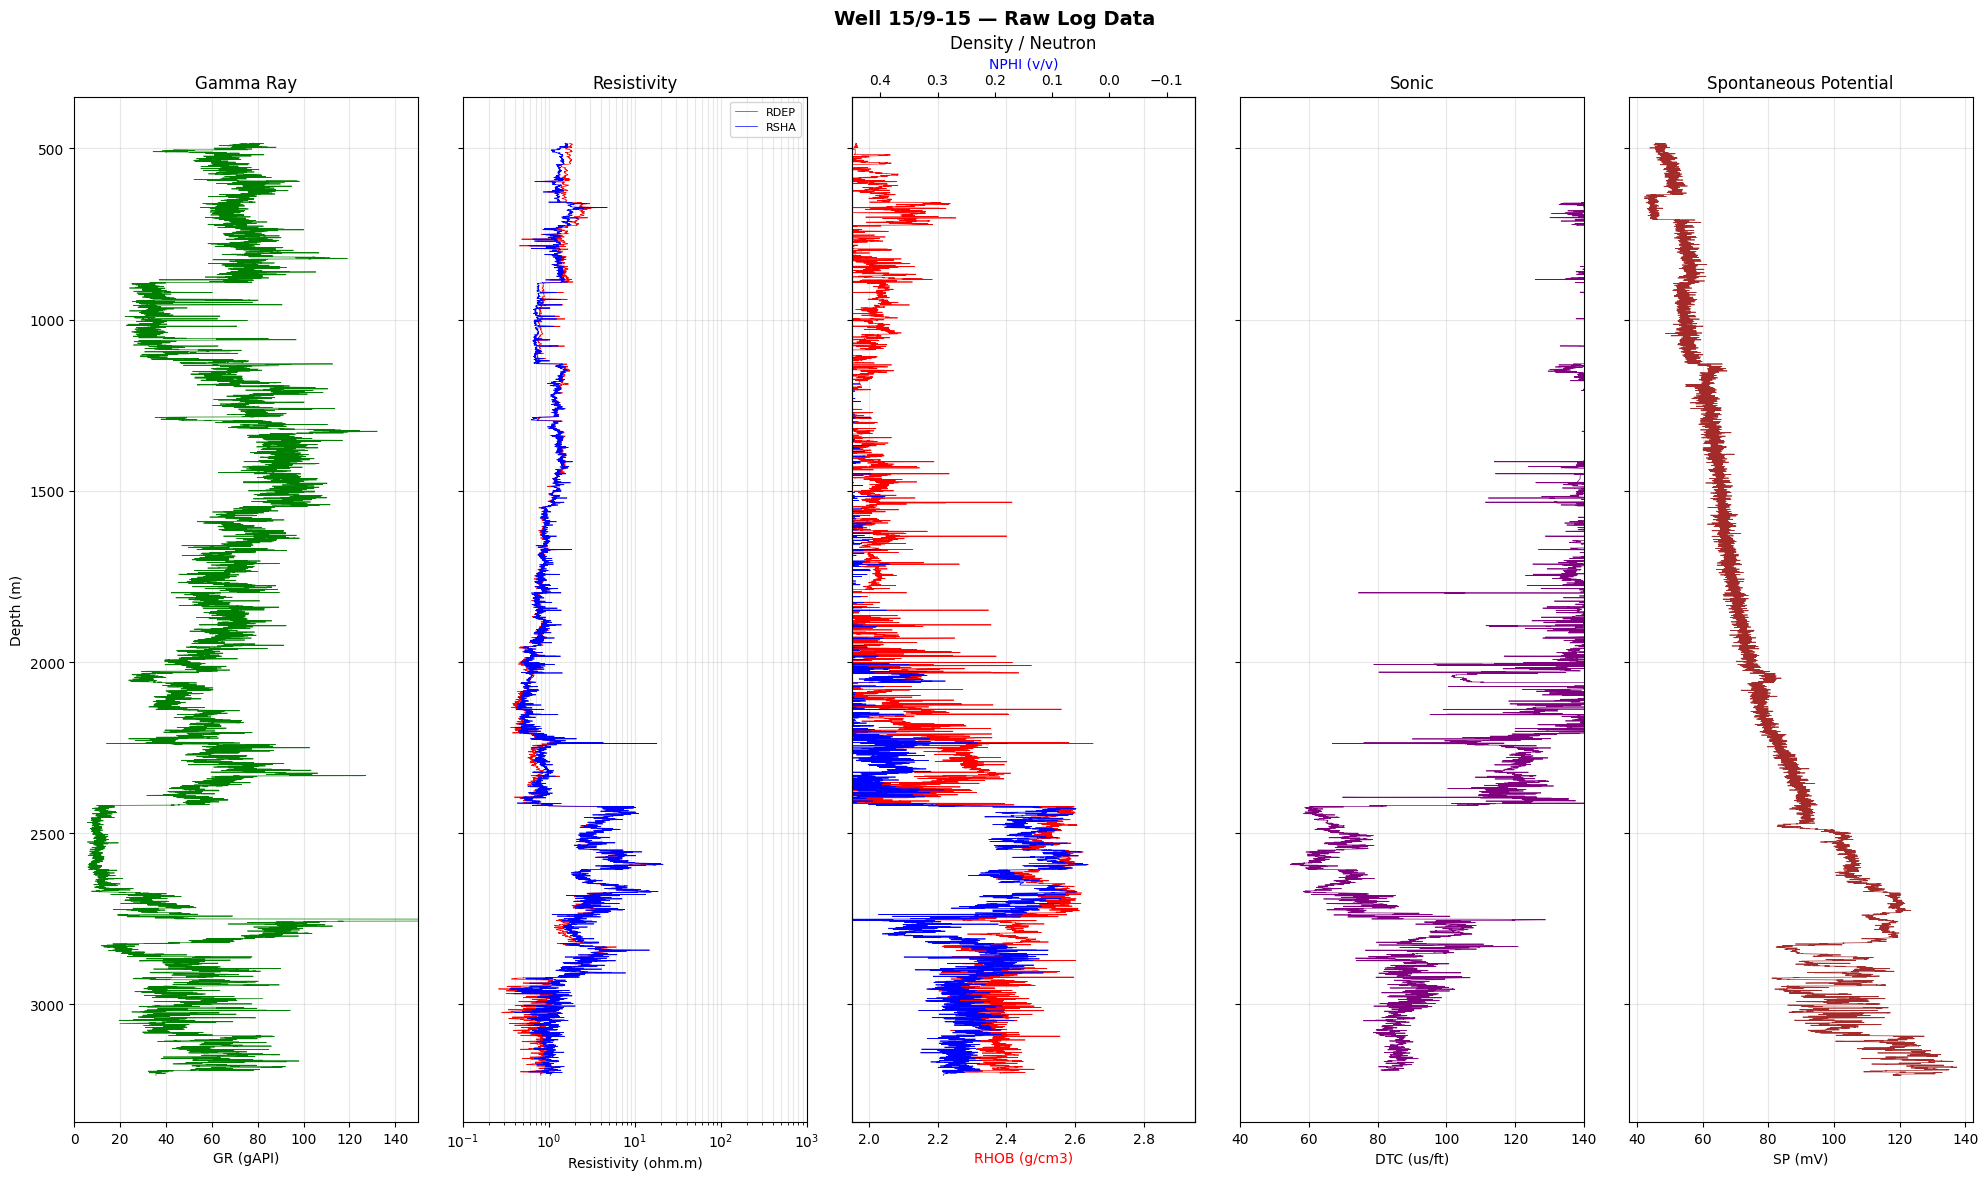

In [5]:
# Quick look at raw log data
fig, axes = plt.subplots(1, 5, figsize=(20, 12), sharey=True)

depth = well.depth

# Track 1: GR
ax = axes[0]
ax.plot(well["GR"].data, depth, 'g', linewidth=0.5)
ax.set_xlabel("GR (gAPI)")
ax.set_ylabel("Depth (m)")
ax.set_xlim(0, 150)
ax.set_title("Gamma Ray")
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

# Track 2: Resistivity
ax = axes[1]
ax.semilogx(well["RDEP"].data, depth, 'r', linewidth=0.5, label='RDEP')
ax.semilogx(well["RSHA"].data, depth, 'b', linewidth=0.5, label='RSHA')
ax.set_xlabel("Resistivity (ohm.m)")
ax.set_xlim(0.1, 1000)
ax.set_title("Resistivity")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, which='both')

# Track 3: Density-Neutron
ax = axes[2]
ax.plot(well["RHOB"].data, depth, 'r', linewidth=0.5, label='RHOB')
ax2 = ax.twiny()
ax2.plot(well["NPHI"].data, depth, 'b', linewidth=0.5, label='NPHI')
ax.set_xlabel("RHOB (g/cm3)", color='r')
ax2.set_xlabel("NPHI (v/v)", color='b')
ax.set_xlim(1.95, 2.95)
ax2.set_xlim(0.45, -0.15)
ax.set_title("Density / Neutron")
ax.grid(True, alpha=0.3)

# Track 4: Sonic
ax = axes[3]
ax.plot(well["DTC"].data, depth, 'purple', linewidth=0.5)
ax.set_xlabel("DTC (us/ft)")
ax.set_xlim(40, 140)
ax.set_title("Sonic")
ax.grid(True, alpha=0.3)

# Track 5: SP
ax = axes[4]
ax.plot(well["SP"].data, depth, 'brown', linewidth=0.5)
ax.set_xlabel("SP (mV)")
ax.set_title("Spontaneous Potential")
ax.grid(True, alpha=0.3)

fig.suptitle(f"Well {well.name} — Raw Log Data", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 2. Curve Standardization (QAQC)

Before running any calculations, we standardize curve names to the library's expected mnemonics. The `CurveStandardizer` auto-maps common aliases (e.g., `Lithology_geolink` stays as-is since it's custom, but `RMED` might get mapped, etc.).

In [6]:
from petrophys.qaqc import CurveStandardizer, standardize_curves

# Show available curve aliases
standardizer = CurveStandardizer(rename_curves=True, convert_units=True)

# Check what the standardizer would do
report = standardizer.report(well)
print("Standardization Report:")
for key, val in report.items():
    print(f"  {key}: {val}")

# Apply standardization
well = standardize_curves(well)
print(f"\nCurves after standardization: {well.curves}")

Standardization Report:
  total_curves: 16
  recognized: [{'original': 'DCAL', 'standard': 'CALI'}, {'original': 'CALI', 'standard': 'CALI'}, {'original': 'BS', 'standard': 'BS'}, {'original': 'DRHO', 'standard': 'DRHO'}, {'original': 'NPHI', 'standard': 'NPHI'}, {'original': 'RHOB', 'standard': 'RHOB'}, {'original': 'PEF', 'standard': 'PEF'}, {'original': 'GR', 'standard': 'GR'}, {'original': 'DTC', 'standard': 'DTC'}, {'original': 'DT', 'standard': 'DTC'}, {'original': 'RDEP', 'standard': 'RDEP'}, {'original': 'SP', 'standard': 'SP'}, {'original': 'RSHA', 'standard': 'RSHA'}, {'original': 'RXO', 'standard': 'RSHA'}, {'original': 'RMED', 'standard': 'RMED'}]
  unrecognized: ['LITHOLOGY_GEOLINK']
  duplicates: [{'type': 'CALI', 'curves': ['DCAL', 'CALI']}, {'type': 'DTC', 'curves': ['DTC', 'DT']}, {'type': 'RSHA', 'curves': ['RSHA', 'RXO']}]
  unit_conversions: [{'curve': 'NPHI', 'from_unit': 'm3/m3', 'to_unit': 'v/v'}, {'curve': 'GR', 'from_unit': 'gAPI', 'to_unit': 'API'}]

Curves af

---
## 3. Linking Lithology & Formation Tops to Log Data

We use the same approach from your `get_df_with_formation_top_geolink` function to:
1. Map `LITHOLOGY_GEOLINK` codes to descriptive lithology names using the nomenclature Excel
2. Load NPD formation tops and assign each depth sample to its formation using `merge_asof`

In [7]:
def normalise_wellname(raw: str) -> str:
    """Normalize NCS-style well names: '15/9-15' -> '15_9-15'."""
    s = str(raw).strip()
    had_underscore = '_' in s
    m = re.match(r'^\s*(\d+)[/_](\d+)\s*([\-\u2013]\s*\d+[A-Za-z0-9]*)?\s*([A-Za-z0-9]+)?\s*$', s)
    if not m:
        s = s.replace('/', '_').strip()
        s = re.sub(r'\s+([A-Za-z0-9]+)$', r'-\1', s)
        if had_underscore:
            s = re.sub(r'(?<!_)\-', '_-', s, count=1)
        return s
    b1, b2, wellpart, trailer = m.groups()
    out = f"{b1}_{b2}"
    if wellpart:
        wellpart = re.sub(r'\s+', '', wellpart)
        out += ('_' + wellpart) if had_underscore else wellpart
    if trailer:
        out += f"-{trailer}"
    return out


def link_lithology_and_tops(las_path, litho_file, tops_file):
    """
    Load a LAS file and merge lithology nomenclature + NPD formation tops.
    Returns (logs_with_formations DataFrame, well_name string).
    """
    # Read lithology nomenclature
    litho_nomenclature = pd.read_excel(litho_file)
    
    # Read LAS
    raw = lasio.read(las_path)
    df = raw.df().reset_index()
    
    # Merge lithology: LITHOLOGY_GEOLINK -> Abbreviation -> Lithology Attribute
    if 'LITHOLOGY_GEOLINK' in df.columns:
        df_merged = df.merge(
            litho_nomenclature,
            left_on='LITHOLOGY_GEOLINK',
            right_on='Abbreviation',
            how='left'
        )
        # Keep original curves + lithology attribute
        keep_cols = list(df.columns) + ['Lithology Attribute']
        keep_cols = [c for c in keep_cols if c in df_merged.columns]
        logs_df = df_merged[keep_cols].copy()
    else:
        logs_df = df.copy()
        logs_df['Lithology Attribute'] = pd.NA
    
    well_name = os.path.basename(las_path).replace('.las', '')
    logs_df['WELL'] = well_name
    logs_df['DEPT'] = pd.to_numeric(logs_df['DEPT'], errors='coerce')
    logs_df = logs_df.dropna(subset=['DEPT']).copy()
    logs_df['WELL'] = logs_df['WELL'].astype(str)
    
    # Read and filter formation tops
    tops_df = (
        pd.read_excel(tops_file, engine='openpyxl')
        .rename(columns={
            'Well identifier': 'RAW_WELL',
            'MD': 'TOP_MD',
            'Surface': 'FORMATION_TOP'
        })
    )
    
    # Remove duplicates
    tops_df = tops_df[
        tops_df.groupby(['RAW_WELL', 'FORMATION_TOP'], dropna=False)['RAW_WELL'].transform('size') == 1
    ]
    
    required = ['RAW_WELL', 'TOP_MD', 'FORMATION_TOP']
    if all(col in tops_df.columns for col in required):
        tops_df['WELL'] = tops_df['RAW_WELL'].apply(normalise_wellname)
        tops_df['TOP_MD'] = pd.to_numeric(tops_df['TOP_MD'], errors='coerce')
        tops_df = tops_df.dropna(subset=['TOP_MD', 'WELL', 'FORMATION_TOP']).copy()
        tops_df['WELL'] = tops_df['WELL'].astype(str)
        tops_df = tops_df[tops_df['WELL'] == well_name].copy()
        
        if not tops_df.empty:
            tops_df = tops_df[['WELL', 'TOP_MD', 'FORMATION_TOP']].sort_values('TOP_MD').reset_index(drop=True)
            print(f"Found {len(tops_df)} formation tops for well '{well_name}'")
        else:
            print(f"No tops found for '{well_name}'")
            tops_df = pd.DataFrame(columns=['WELL', 'TOP_MD', 'FORMATION_TOP'])
    else:
        tops_df = pd.DataFrame(columns=['WELL', 'TOP_MD', 'FORMATION_TOP'])
    
    tops_df['WELL'] = tops_df['WELL'].astype(str)
    logs_df = logs_df.sort_values('DEPT').reset_index(drop=True)
    
    # merge_asof: assign each depth to the formation whose top is at or above it
    logs_with_top = pd.merge_asof(
        logs_df, tops_df,
        left_on='DEPT', right_on='TOP_MD',
        by='WELL', direction='backward', allow_exact_matches=True
    ).rename(columns={'FORMATION_TOP': 'FORMATION'})
    
    if 'TOP_MD' in logs_with_top.columns:
        logs_with_top.drop(columns=['TOP_MD'], inplace=True)
    if 'FORMATION' not in logs_with_top.columns:
        logs_with_top['FORMATION'] = pd.NA
    
    logs_with_top.drop(columns=['WELL'], errors='ignore', inplace=True)
    
    return logs_with_top, well_name, tops_df

# Apply to our primary well
logs_df, well_name, tops_15_9 = link_lithology_and_tops(
    os.path.join(LAS_DIR, "15_9-15.las"), LITHO_FILE, TOPS_FILE
)

print(f"\nWell: {well_name}")
print(f"DataFrame shape: {logs_df.shape}")
print(f"\nFormation top assignments (sample):")
print(logs_df[['DEPT', 'FORMATION', 'Lithology Attribute']].dropna(subset=['FORMATION']).head(20))

Found 18 formation tops for well '15_9-15'

Well: 15_9-15
DataFrame shape: (17864, 19)

Formation top assignments (sample):
          DEPT         FORMATION Lithology Attribute
0   485.028839  NORDLAND GP. Top                 NaN
1   485.181244  NORDLAND GP. Top                 NaN
2   485.333649  NORDLAND GP. Top                 NaN
3   485.486053  NORDLAND GP. Top                 NaN
4   485.638458  NORDLAND GP. Top                 NaN
5   485.790863  NORDLAND GP. Top                 NaN
6   485.943268  NORDLAND GP. Top                 NaN
7   486.095642  NORDLAND GP. Top                 NaN
8   486.248047  NORDLAND GP. Top                 NaN
9   486.400452  NORDLAND GP. Top                 NaN
10  486.552856  NORDLAND GP. Top                 NaN
11  486.705261  NORDLAND GP. Top                 NaN
12  486.857666  NORDLAND GP. Top                 NaN
13  487.010071  NORDLAND GP. Top                 NaN
14  487.162445  NORDLAND GP. Top                 NaN
15  487.314819  NORDLAND GP.

In [ ]:
# ============================================================
# Map LITHOLOGY_GEOLINK codes to descriptive names on the Well object
# ============================================================
# The Well object has numeric codes (1, 2, 7...) in LITHOLOGY_GEOLINK
# We need to map these to names ("Sand", "Shale", etc.) from the nomenclature file

litho_nomenclature = pd.read_excel(LITHO_FILE)

# Build a lookup: Abbreviation (int) -> Lithology Attribute (string)
litho_lookup = dict(zip(litho_nomenclature['Abbreviation'], litho_nomenclature['Lithology Attribute']))
print("Lithology code mapping:")
for code, name in sorted(litho_lookup.items()):
    print(f"  {code:3d} -> {name}")

# Map codes on the Well object to lithology names
geolink_data = well["LITHOLOGY_GEOLINK"].data
lithology_names = np.array([""] * len(geolink_data), dtype=object)

for code, name in litho_lookup.items():
    mask = np.isclose(geolink_data, float(code), atol=0.1) & ~np.isnan(geolink_data)
    lithology_names[mask] = name

# Also build a clastic/carbonate classification for the library's Sw routing
carbonate_types = {"Chalk", "Limestone", "Dolomite2", "Calcareous Shale", 
                   "Sandy Limestone", "Calcareous Sandstone"}
litho_class = np.array(["clastic"] * len(geolink_data), dtype=object)
for i, name in enumerate(lithology_names):
    if name in carbonate_types:
        litho_class[i] = "carbonate"

# Add to Well
well.add_curve("LITHOLOGY", lithology_names, "", "Lithology Name (from Geolink)")
well.add_curve("LITHO_CLASS", litho_class, "", "Lithology Classification (clastic/carbonate)")

# Summary
unique_names, counts = np.unique(lithology_names[lithology_names != ""], return_counts=True)
print(f"\nLithology mapped: {np.sum(lithology_names != '')} of {len(lithology_names)} samples")
print("\nLithology distribution:")
for name, count in sorted(zip(unique_names, counts), key=lambda x: -x[1]):
    print(f"  {name:<25s} {count:>6d} samples")

In [ ]:
# Visualize the lithology log alongside GR
fig, axes = plt.subplots(1, 3, figsize=(14, 14), sharey=True)

depth = well.depth

# Track 1: GR
ax = axes[0]
ax.plot(well["GR"].data, depth, 'g', linewidth=0.5)
ax.set_xlabel("GR (gAPI)")
ax.set_ylabel("Depth (m)")
ax.set_xlim(0, 150)
ax.set_title("Gamma Ray")
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

# Track 2: Lithology color column
ax = axes[1]
litho_color_map = {
    "Sand": "yellow", "CrossBedded Sand": "gold", "Silt": "lightsalmon",
    "Shaly Sandstone": "sandybrown", "Shale": "gray", "Chalk": "lightblue",
    "Limestone": "dodgerblue", "Sandy Limestone": "steelblue",
    "Calcareous Sandstone": "cadetblue", "Calcareous Shale": "darkgray",
    "Dolomite2": "cyan", "Extrusive": "red", "Coal": "black",
    "Conglomerate": "orange", "Halite": "pink",
}
for litho_name, color in litho_color_map.items():
    mask = lithology_names == litho_name
    if np.any(mask):
        ax.fill_betweenx(depth, 0, 1, where=mask, color=color, alpha=0.8, label=litho_name)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.set_title("Lithology (Geolink)")
ax.legend(loc='lower left', fontsize=6, ncol=2)

# Track 3: Litho class (clastic/carbonate)
ax = axes[2]
carb_mask = litho_class == "carbonate"
clas_mask = (litho_class == "clastic") & (lithology_names != "")
ax.fill_betweenx(depth, 0, 1, where=clas_mask, color='yellow', alpha=0.6, label='Clastic')
ax.fill_betweenx(depth, 0, 1, where=carb_mask, color='dodgerblue', alpha=0.6, label='Carbonate')
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.set_title("Lithology Class")
ax.legend(fontsize=8)

fig.suptitle(f"Well {well.name} — Lithology from Geolink Codes", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

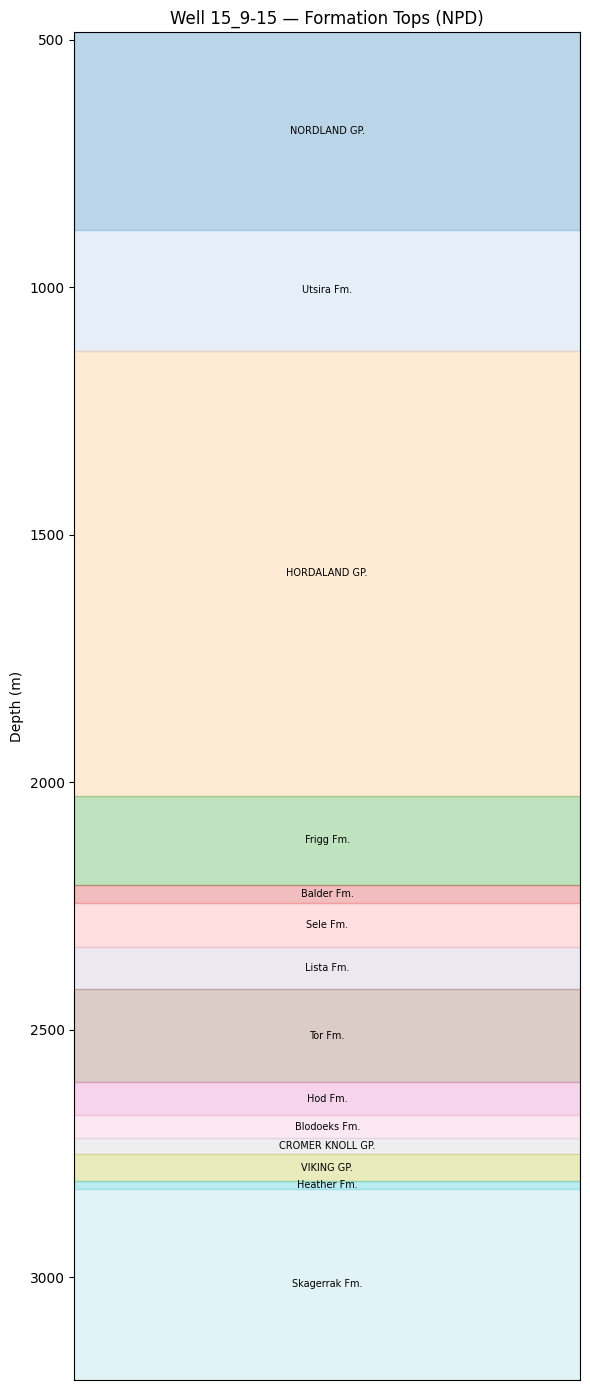

In [8]:
# Visualize formations along the well
fig, ax = plt.subplots(figsize=(6, 14))

formations = logs_df.dropna(subset=['FORMATION'])
unique_fms = formations['FORMATION'].unique()
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_fms)))
fm_color_map = dict(zip(unique_fms, colors))

for fm_name in unique_fms:
    fm_data = formations[formations['FORMATION'] == fm_name]
    ax.axhspan(fm_data['DEPT'].min(), fm_data['DEPT'].max(), 
               alpha=0.3, color=fm_color_map[fm_name], label=fm_name)
    mid_depth = (fm_data['DEPT'].min() + fm_data['DEPT'].max()) / 2
    ax.text(0.5, mid_depth, fm_name.replace(' Top', ''), 
            transform=ax.get_yaxis_transform(), fontsize=7, ha='center', va='center')

ax.set_ylim(well.bottom, well.top)
ax.set_ylabel("Depth (m)")
ax.set_title(f"Well {well_name} — Formation Tops (NPD)")
ax.set_xticks([])
plt.tight_layout()
plt.show()

---
## 4. Clay Volume (VCL) Calculation

The library supports multiple VCL methods:
- **GR-based**: Linear, Larionov (Tertiary/Older Rocks), Steiber, Clavier
- **SP-based**: From spontaneous potential deflection
- **Neutron-Density**: From N-D crossplot separation

The `VclModule` automatically combines available methods, or you can call individual functions.

GR endpoints: GR_min=11.0, GR_max=94.6


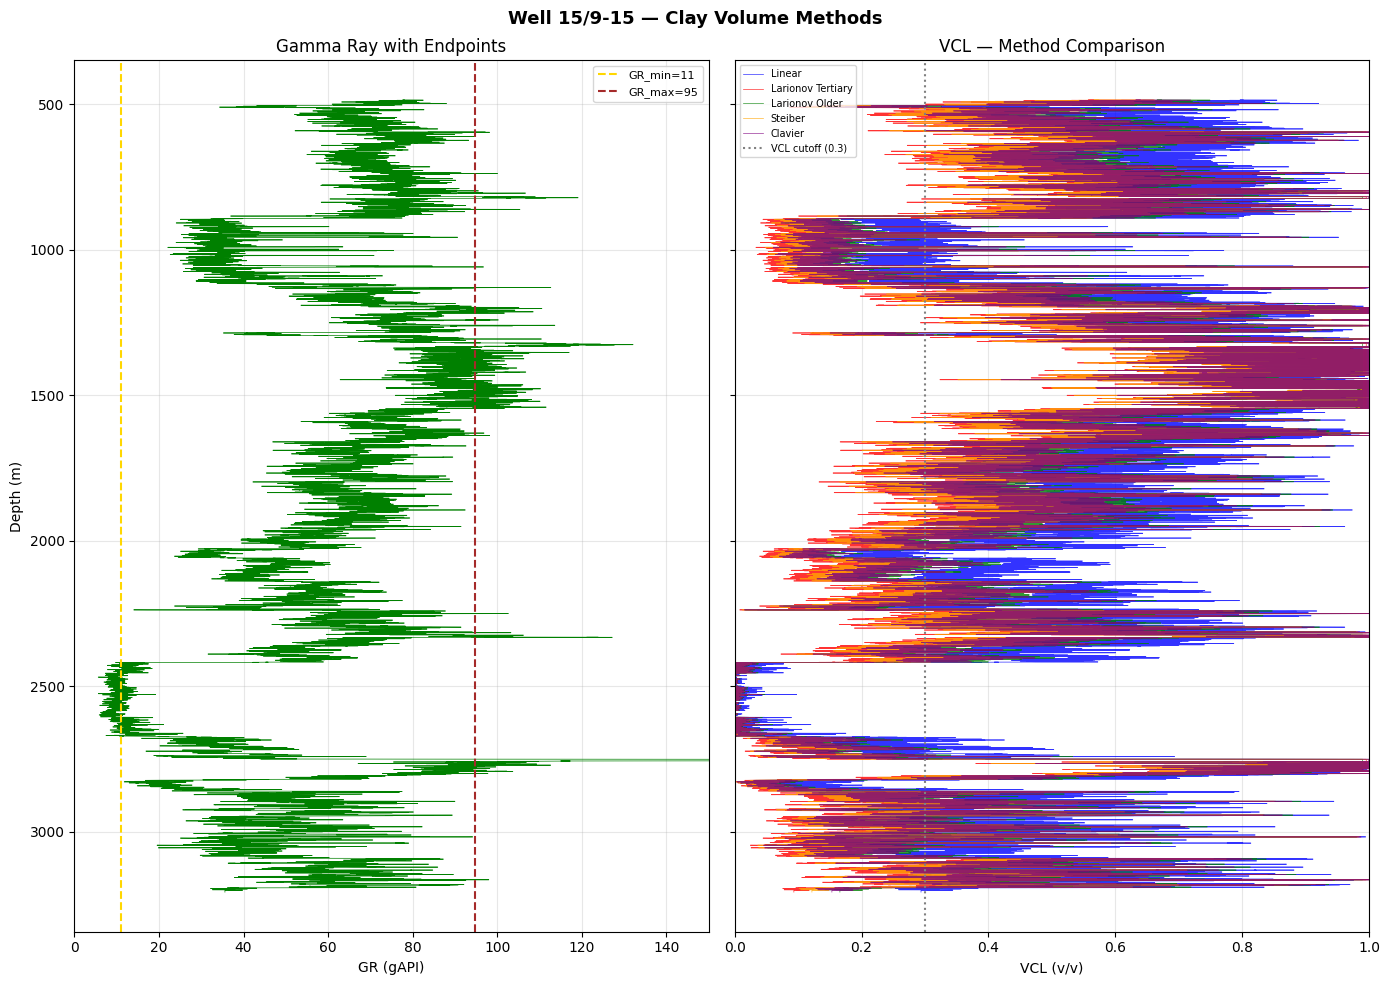

In [9]:
from petrophys.clay_volume import (
    vcl_from_gr, vcl_linear, vcl_larionov_tertiary, 
    vcl_larionov_older, vcl_steiber, vcl_clavier,
    vcl_from_sp, vcl_from_nd,
    VclModule, calculate_vcl
)

# --- Method 1: Individual GR-based functions ---
gr = well["GR"].data

# Determine GR clean/shale endpoints from histogram
valid_gr = gr[~np.isnan(gr)]
gr_min = float(np.percentile(valid_gr, 5))   # Clean sand line
gr_max = float(np.percentile(valid_gr, 95))   # Shale line
print(f"GR endpoints: GR_min={gr_min:.1f}, GR_max={gr_max:.1f}")

# Compute IGR (gamma ray index) using the linear method first
igr = vcl_linear(gr, gr_min, gr_max)

# Compare all GR nonlinear methods
vcl_methods = {
    "Linear":             igr,
    "Larionov Tertiary":  vcl_larionov_tertiary(igr),
    "Larionov Older":     vcl_larionov_older(igr),
    "Steiber":            vcl_steiber(igr),
    "Clavier":            vcl_clavier(igr),
}

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 10), sharey=True)

# GR with endpoints
ax = axes[0]
ax.plot(gr, well.depth, 'g', linewidth=0.5)
ax.axvline(gr_min, color='gold', linestyle='--', label=f'GR_min={gr_min:.0f}')
ax.axvline(gr_max, color='brown', linestyle='--', label=f'GR_max={gr_max:.0f}')
ax.set_xlabel("GR (gAPI)")
ax.set_ylabel("Depth (m)")
ax.set_title("Gamma Ray with Endpoints")
ax.set_xlim(0, 150)
ax.legend(fontsize=8)
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

# VCL comparison
ax = axes[1]
colors_vcl = ['blue', 'red', 'green', 'orange', 'purple']
for (name, vcl_arr), color in zip(vcl_methods.items(), colors_vcl):
    ax.plot(vcl_arr, well.depth, color=color, linewidth=0.5, label=name, alpha=0.8)
ax.axvline(0.3, color='gray', linestyle=':', label='VCL cutoff (0.3)')
ax.set_xlabel("VCL (v/v)")
ax.set_title("VCL — Method Comparison")
ax.set_xlim(0, 1)
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

fig.suptitle(f"Well {well.name} — Clay Volume Methods", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# --- Method 2: VclModule (recommended) ---
# The module auto-combines GR + SP + N-D methods and picks the minimum VCL

vcl_module = VclModule(
    gr_min=gr_min,
    gr_max=gr_max,
    gr_method="larionov_tertiary",  # North Sea Tertiary rocks
    use_sp=True,                     # Well has SP curve
    use_nd=True,                     # Well has NPHI + RHOB
)

vcl_result = vcl_module.calculate(well)

print(f"VCL result attributes: vcl, vcl_gr, vcl_sp, vcl_nd")
print(f"VCL range: {np.nanmin(vcl_result.vcl):.3f} - {np.nanmax(vcl_result.vcl):.3f}")
print(f"VCL_GR available: {vcl_result.vcl_gr is not None}")
print(f"VCL_SP available: {vcl_result.vcl_sp is not None}")
print(f"VCL_ND available: {vcl_result.vcl_nd is not None}")

# Add VCL to the well object
vcl_module.add_to_well(well, vcl_result)
print(f"\nVCL curve added. Well now has: {well.curves}")

VCL result attributes: vcl, vcl_gr, vcl_sp, vcl_nd
VCL range: 0.000 - 0.996
VCL_GR available: True
VCL_SP available: True
VCL_ND available: True

VCL curve added. Well now has: ['LITHOLOGY_GEOLINK', 'CALI', 'BS', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DT', 'RDEP', 'SP', 'RSHA', 'RMED', 'VCL', 'VCLGR', 'VCLSP', 'VCLND']


In [11]:
# --- Method 3: One-liner convenience function ---
# calculate_vcl(well, ...) is a shortcut that creates VclModule + calculates + returns result

vcl_result_quick = calculate_vcl(well, gr_min=gr_min, gr_max=gr_max, gr_method="steiber")
print(f"Quick VCL range: {np.nanmin(vcl_result_quick.vcl):.3f} - {np.nanmax(vcl_result_quick.vcl):.3f}")

Quick VCL range: 0.000 - 1.000


---
## 5. Porosity Calculation

The library calculates:
- **Density Porosity (PHID)**: From RHOB, matrix density, fluid density
- **Neutron-Density Total Porosity (PHIT)**: Adaptive combination of NPHI and PHID
- **Sonic Porosity (PHIS)**: Wyllie time-average from DTC
- **Effective Porosity (PHIE)**: Clay-corrected porosity = PHIT - VCL x PHI_clay

In [12]:
from petrophys.petrophysics.porosity import (
    density_porosity, sonic_porosity, total_porosity, effective_porosity,
    PorosityModule
)

# --- Individual porosity functions ---

# Density porosity: PHID = (rho_ma - RHOB) / (rho_ma - rho_fl)
rhob = well["RHOB"].data
phid = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)  # Sandstone matrix
print(f"PHID range: {np.nanmin(phid):.3f} to {np.nanmax(phid):.3f}")

# Sonic porosity: Wyllie time-average
dtc = well["DTC"].data
phis = sonic_porosity(dtc, matrix="sandstone", dtc_fluid=189.0, compaction_factor=1.0)
print(f"PHIS range: {np.nanmin(phis):.3f} to {np.nanmax(phis):.3f}")

# Total porosity: adaptive N-D combination
nphi = well["NPHI"].data
phit = total_porosity(nphi, phid, method="adaptive")
print(f"PHIT range: {np.nanmin(phit):.3f} to {np.nanmax(phit):.3f}")

# Effective porosity: clay correction
vcl = well["VCL"].data
phie = effective_porosity(phit, vcl, phi_clay=0.15)
print(f"PHIE range: {np.nanmin(phie):.3f} to {np.nanmax(phie):.3f}")

# Add to well
well.add_curve("PHID", phid, "v/v", "Density Porosity")
well.add_curve("PHIS", phis, "v/v", "Sonic Porosity")
well.add_curve("PHIT", phit, "v/v", "Total Porosity (N-D)")
well.add_curve("PHIE", phie, "v/v", "Effective Porosity")

PHID range: 0.000 to 0.500
PHIS range: 0.000 to 0.500
PHIT range: 0.000 to 0.500
PHIE range: 0.000 to 0.500


Curve(PHIE, unit=v/v, samples=17864)

In [13]:
# --- Using PorosityModule (recommended for workflow integration) ---
# The module auto-detects available curves and computes all porosity types

por_module = PorosityModule(
    matrix="sandstone",    # matrix type
    rhob_fluid=1.0,        # fluid density
    phi_clay=0.15          # clay bound-water porosity
)
por_result = por_module.calculate(well)
# por_module.add_to_well(well, por_result)  # Would overwrite our curves

print(f"PorosityModule computed successfully")
print(f"  Porosity attributes available on result object")

PorosityModule computed successfully
  Porosity attributes available on result object


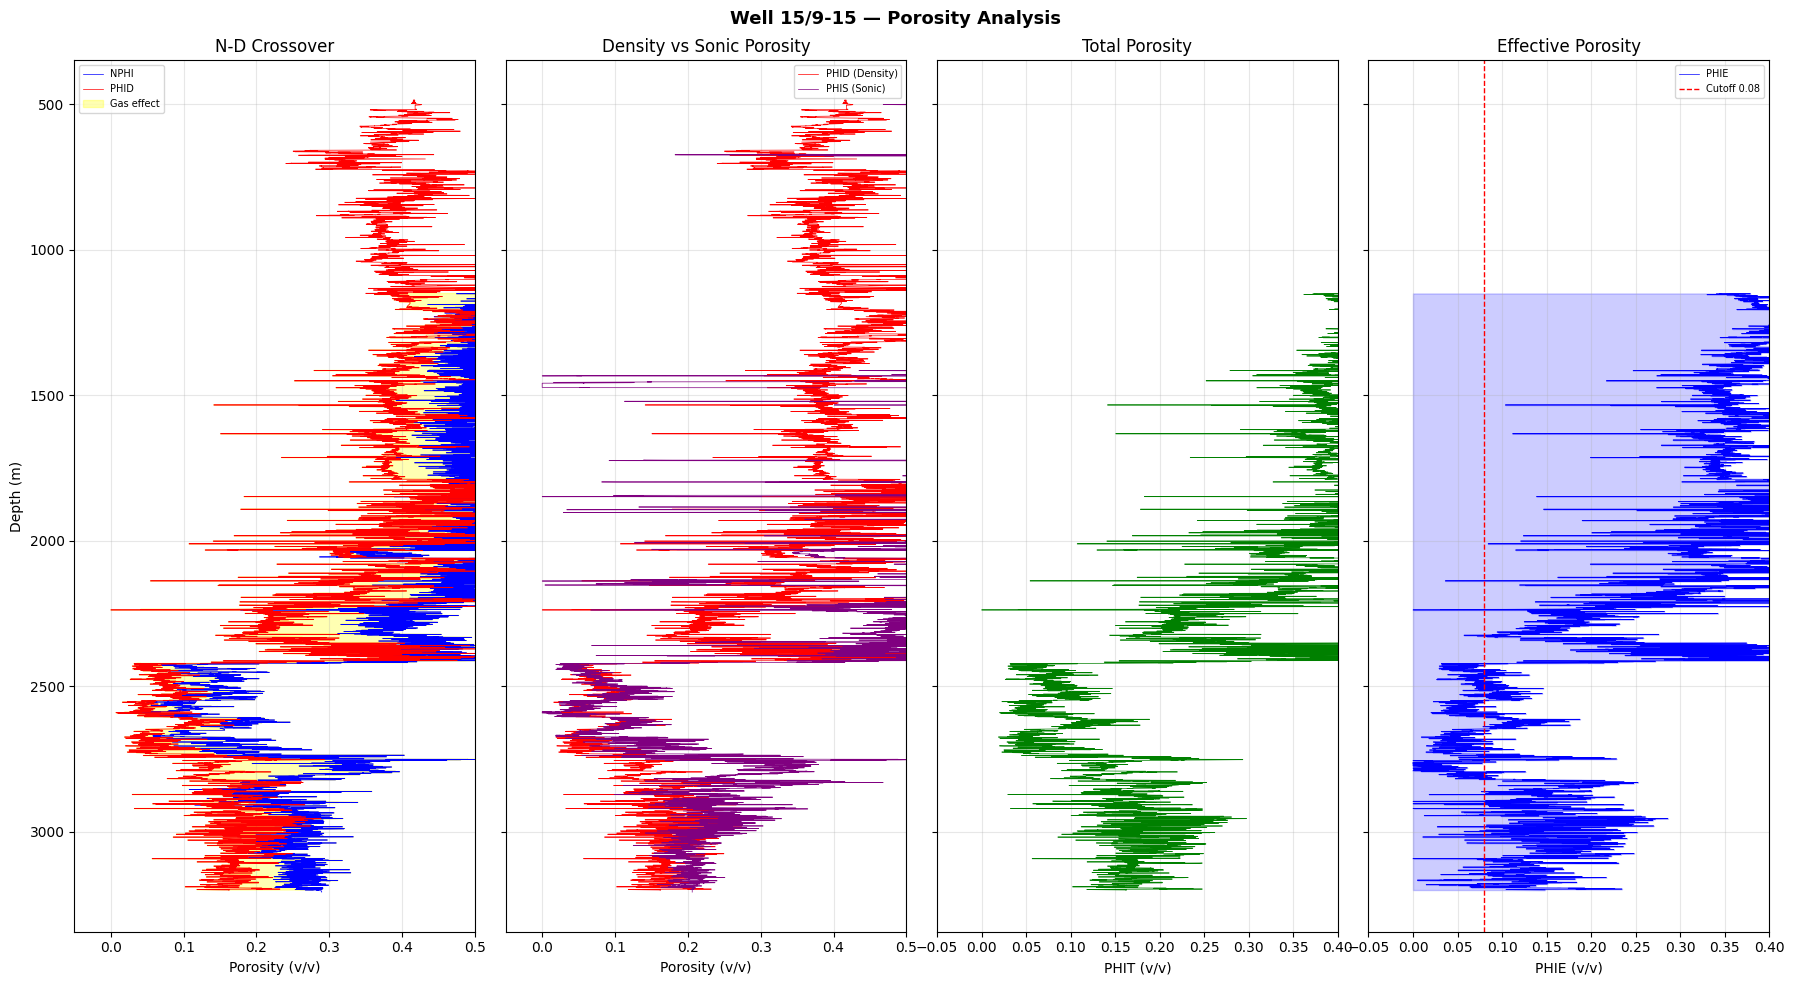

In [14]:
# Plot porosity comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 10), sharey=True)

depth = well.depth

# Track 1: Density-Neutron overlay
ax = axes[0]
ax.plot(well["NPHI"].data, depth, 'b', linewidth=0.5, label='NPHI')
ax.plot(phid, depth, 'r', linewidth=0.5, label='PHID')
ax.fill_betweenx(depth, well["NPHI"].data, phid, 
                  where=(well["NPHI"].data > phid), color='yellow', alpha=0.3, label='Gas effect')
ax.set_xlabel("Porosity (v/v)")
ax.set_ylabel("Depth (m)")
ax.set_xlim(-0.05, 0.5)
ax.set_title("N-D Crossover")
ax.legend(fontsize=7)
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

# Track 2: PHID vs PHIS
ax = axes[1]
ax.plot(phid, depth, 'r', linewidth=0.5, label='PHID (Density)')
ax.plot(phis, depth, 'purple', linewidth=0.5, label='PHIS (Sonic)')
ax.set_xlabel("Porosity (v/v)")
ax.set_xlim(-0.05, 0.5)
ax.set_title("Density vs Sonic Porosity")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# Track 3: PHIT
ax = axes[2]
ax.plot(phit, depth, 'green', linewidth=0.5)
ax.set_xlabel("PHIT (v/v)")
ax.set_xlim(-0.05, 0.4)
ax.set_title("Total Porosity")
ax.grid(True, alpha=0.3)

# Track 4: PHIE (effective)
ax = axes[3]
ax.plot(phie, depth, 'blue', linewidth=0.5, label='PHIE')
ax.fill_betweenx(depth, 0, phie, alpha=0.2, color='blue')
ax.axvline(0.08, color='red', linestyle='--', linewidth=1, label='Cutoff 0.08')
ax.set_xlabel("PHIE (v/v)")
ax.set_xlim(-0.05, 0.4)
ax.set_title("Effective Porosity")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

fig.suptitle(f"Well {well.name} — Porosity Analysis", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 6. Water Saturation (Sw) — Archie, Simandoux, Indonesia

The library supports multiple Sw models:
- **Archie**: Clean sands (Sw^n = a*Rw / (phi^m * Rt))
- **Simandoux**: Shaly sands (accounts for VCL and Rcl)
- **Indonesia**: Shaly sands, particularly SE Asian formations
- **Dual Water / Waxman-Smits**: Advanced shaly sand models

For this tutorial, we use **synthetic Rw and temperature** since these aren't in the LAS file:
- BHT = 220 F at TD = 3207 m (typical North Sea)
- Rw = 0.04 ohm.m at formation temperature (saline formation water)
- Rmf = 0.5 ohm.m at 75 F (WBM mud filtrate)

In [15]:
from petrophys.petrophysics.saturation import archie, simandoux, indonesia
from petrophys.clay_volume.rcl import calculate_rcl
from petrophys.environmental.temperature import arps_equation

# Synthetic parameters (typical North Sea values)
RW = 0.04       # Rw at formation temperature (ohm.m) — saline formation water
RMF = 0.5       # Rmf at surface (75 F)
A = 1.0         # Tortuosity factor
M = 2.0         # Cementation exponent
N = 2.0         # Saturation exponent

# Estimate clay resistivity from deep resistivity in shale zones
rcl = calculate_rcl(well["RDEP"].data, well["VCL"].data, vcl_threshold=0.9, default_rcl=5.0)
print(f"Estimated Rcl: {rcl:.2f} ohm.m")

# Get the deep resistivity
rt = well["RDEP"].data

# --- Archie (clean sand model) ---
sw_archie = archie(rt, RW, phie, a=A, m=M, n=N)

# --- Simandoux (shaly sand) ---
sw_simandoux = simandoux(rt, RW, phie, vcl, rcl, a=A, m=M, n=N)

# --- Indonesia (shaly sand) ---
sw_indonesia = indonesia(rt, RW, phie, vcl, rcl, a=A, m=M, n=N)

# Clip to [0, 1]
sw_archie = np.clip(sw_archie, 0, 1)
sw_simandoux = np.clip(sw_simandoux, 0, 1)
sw_indonesia = np.clip(sw_indonesia, 0, 1)

print(f"\nSw Archie range:     {np.nanmin(sw_archie):.3f} - {np.nanmax(sw_archie):.3f}")
print(f"Sw Simandoux range:  {np.nanmin(sw_simandoux):.3f} - {np.nanmax(sw_simandoux):.3f}")
print(f"Sw Indonesia range:  {np.nanmin(sw_indonesia):.3f} - {np.nanmax(sw_indonesia):.3f}")

Estimated Rcl: 1.43 ohm.m

Sw Archie range:     0.329 - 1.000
Sw Simandoux range:  0.000 - 1.000
Sw Indonesia range:  0.000 - 1.000


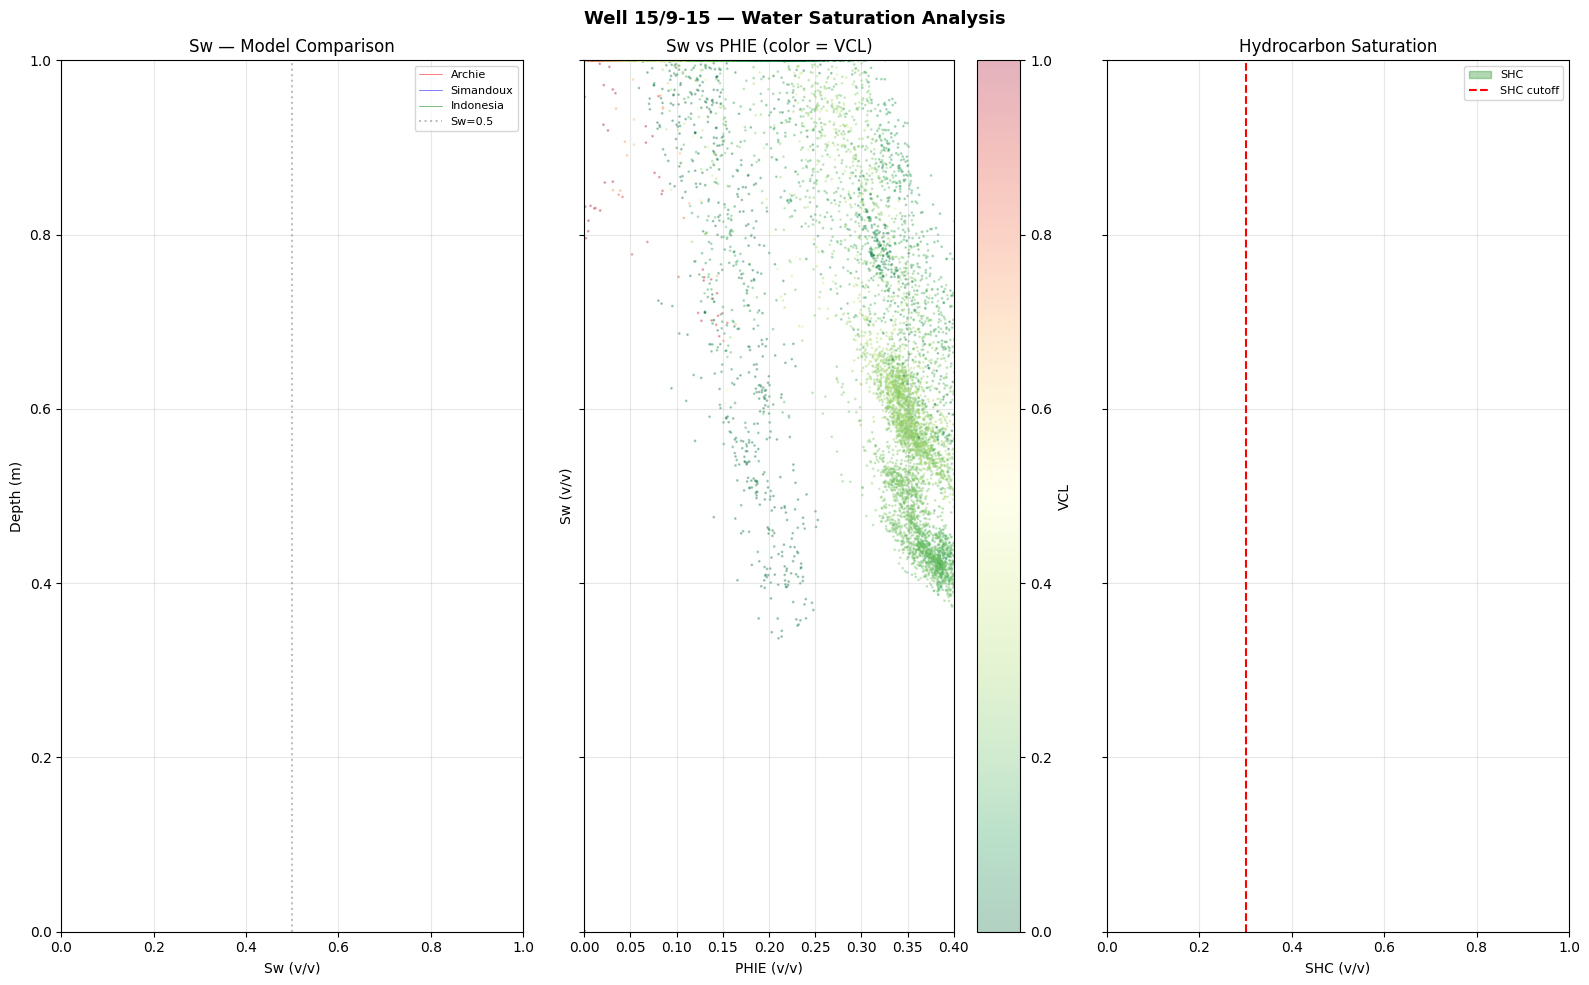

In [16]:
# Use Simandoux as the final Sw (good for North Sea shaly sands)
well.add_curve("SW", sw_simandoux, "v/v", "Water Saturation (Simandoux)")

# Plot Sw comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 10), sharey=True)

ax = axes[0]
ax.plot(sw_archie, depth, 'r', linewidth=0.5, alpha=0.7, label='Archie')
ax.plot(sw_simandoux, depth, 'b', linewidth=0.5, alpha=0.7, label='Simandoux')
ax.plot(sw_indonesia, depth, 'g', linewidth=0.5, alpha=0.7, label='Indonesia')
ax.axvline(0.5, color='gray', linestyle=':', alpha=0.5, label='Sw=0.5')
ax.set_xlabel("Sw (v/v)")
ax.set_ylabel("Depth (m)")
ax.set_xlim(0, 1)
ax.set_title("Sw — Model Comparison")
ax.legend(fontsize=8)
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

# Sw vs PHIE crossplot colored by VCL
ax = axes[1]
valid = ~(np.isnan(phie) | np.isnan(sw_simandoux) | np.isnan(vcl))
sc = ax.scatter(phie[valid], sw_simandoux[valid], c=vcl[valid], 
                cmap='RdYlGn_r', s=1, alpha=0.3, vmin=0, vmax=1)
ax.set_xlabel("PHIE (v/v)")
ax.set_ylabel("Sw (v/v)")
ax.set_title("Sw vs PHIE (color = VCL)")
ax.set_xlim(0, 0.4)
ax.set_ylim(0, 1)
plt.colorbar(sc, ax=ax, label='VCL')
ax.grid(True, alpha=0.3)

# Hydrocarbon saturation (1 - Sw)
ax = axes[2]
shc = 1 - sw_simandoux
ax.fill_betweenx(depth, 0, shc, color='green', alpha=0.3, label='SHC')
ax.axvline(0.3, color='red', linestyle='--', label='SHC cutoff')
ax.set_xlabel("SHC (v/v)")
ax.set_xlim(0, 1)
ax.set_title("Hydrocarbon Saturation")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

fig.suptitle(f"Well {well.name} — Water Saturation Analysis", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 7. Permeability Estimation

Available methods:
- **Timur**: k = 8581 * phi^4.4 / Swi^2 (general empirical)
- **Coates-Denoo**: k = 100^2 * (phi*(1-Swi)/Swi)^2
- **Wyllie-Rose**: k = 250 * phi^3 / Swi^2

We estimate irreducible water saturation (Swirr) from Sw in net pay zones.

Estimated Swirr: 0.767
Timur Perm range:  0.00 - 691.53 mD
Coates Perm range: 0.00 - 231.61 mD


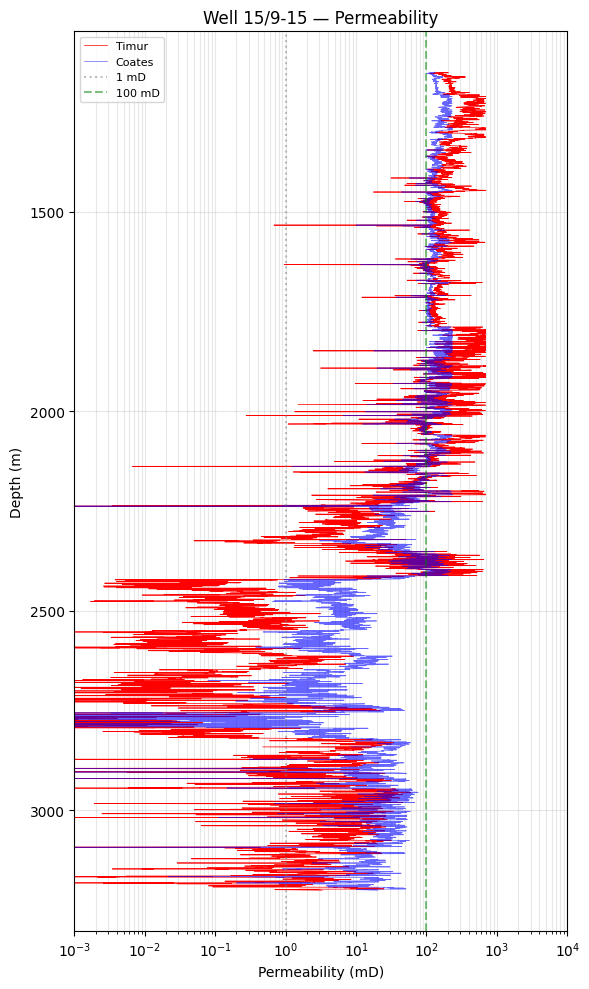

In [17]:
from petrophys.petrophysics.permeability import timur, coates_denoo, PermeabilityModule

# Estimate Swirr: use Sw in clean, porous zones as a proxy
clean_mask = (vcl < 0.15) & (phie > 0.1) & ~np.isnan(sw_simandoux)
if np.any(clean_mask):
    swirr = float(np.nanmean(sw_simandoux[clean_mask]))
else:
    swirr = 0.25  # Default
print(f"Estimated Swirr: {swirr:.3f}")

# --- Individual functions ---
perm_timur = timur(phie, swirr)
perm_coates = coates_denoo(phie, swirr)

print(f"Timur Perm range:  {np.nanmin(perm_timur):.2f} - {np.nanmax(perm_timur):.2f} mD")
print(f"Coates Perm range: {np.nanmin(perm_coates):.2f} - {np.nanmax(perm_coates):.2f} mD")

# Use Timur as our final permeability
well.add_curve("PERM", perm_timur, "mD", "Permeability (Timur)")

# Plot
fig, ax = plt.subplots(figsize=(6, 10))
ax.semilogx(perm_timur, depth, 'r', linewidth=0.5, label='Timur')
ax.semilogx(perm_coates, depth, 'b', linewidth=0.5, alpha=0.6, label='Coates')
ax.axvline(1, color='gray', linestyle=':', alpha=0.5, label='1 mD')
ax.axvline(100, color='green', linestyle='--', alpha=0.5, label='100 mD')
ax.set_xlabel("Permeability (mD)")
ax.set_ylabel("Depth (m)")
ax.set_xlim(0.001, 10000)
ax.set_title(f"Well {well.name} — Permeability")
ax.legend(fontsize=8)
ax.invert_yaxis()
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

---
## 8. Net Pay Determination

Net pay flags determine which depth intervals qualify as producible hydrocarbon-bearing rock. The `NetPayModule` applies cutoffs:
- **VCL cutoff**: e.g., VCL < 0.3 (net rock)
- **PHIE cutoff**: e.g., PHIE > 0.08 (net reservoir)
- **Sw cutoff**: e.g., Sw < 0.7 (net pay)

The module creates three flag curves: `NET_ROCK`, `NET_RES`, `NET_PAY`.

In [18]:
from petrophys.reservoir.net_pay import NetPayModule

# Create net pay module with standard cutoffs
np_module = NetPayModule(
    vcl_cutoff=0.30,     # VCL < 0.30 = net rock
    phie_cutoff=0.08,    # PHIE > 0.08 = net reservoir
    sw_cutoff=0.70,      # Sw < 0.70 = net pay
)

np_result = np_module.calculate(well)
np_module.add_to_well(well, np_result)

# Compute statistics
depth = well.depth
step = np.nanmedian(np.diff(depth))  # average depth step
n_total = len(depth)
n_rock = np.nansum(well["NET_ROCK"].data > 0.5)
n_res = np.nansum(well["NET_RES"].data > 0.5)
n_pay = np.nansum(well["NET_PAY"].data > 0.5)

print(f"Depth step: {step:.3f} m")
print(f"Total interval:   {n_total * step:.1f} m ({n_total} samples)")
print(f"Net Rock:         {n_rock * step:.1f} m ({n_rock} samples)")
print(f"Net Reservoir:    {n_res * step:.1f} m ({n_res} samples)")
print(f"Net Pay:          {n_pay * step:.1f} m ({n_pay} samples)")
print(f"Net-to-Gross:     {n_pay/n_total:.1%}")

Depth step: 0.152 m
Total interval:   2721.5 m (17864 samples)
Net Rock:         2428.4 m (15940 samples)
Net Reservoir:    1548.3 m (10163 samples)
Net Pay:          876.3 m (5752 samples)
Net-to-Gross:     32.2%


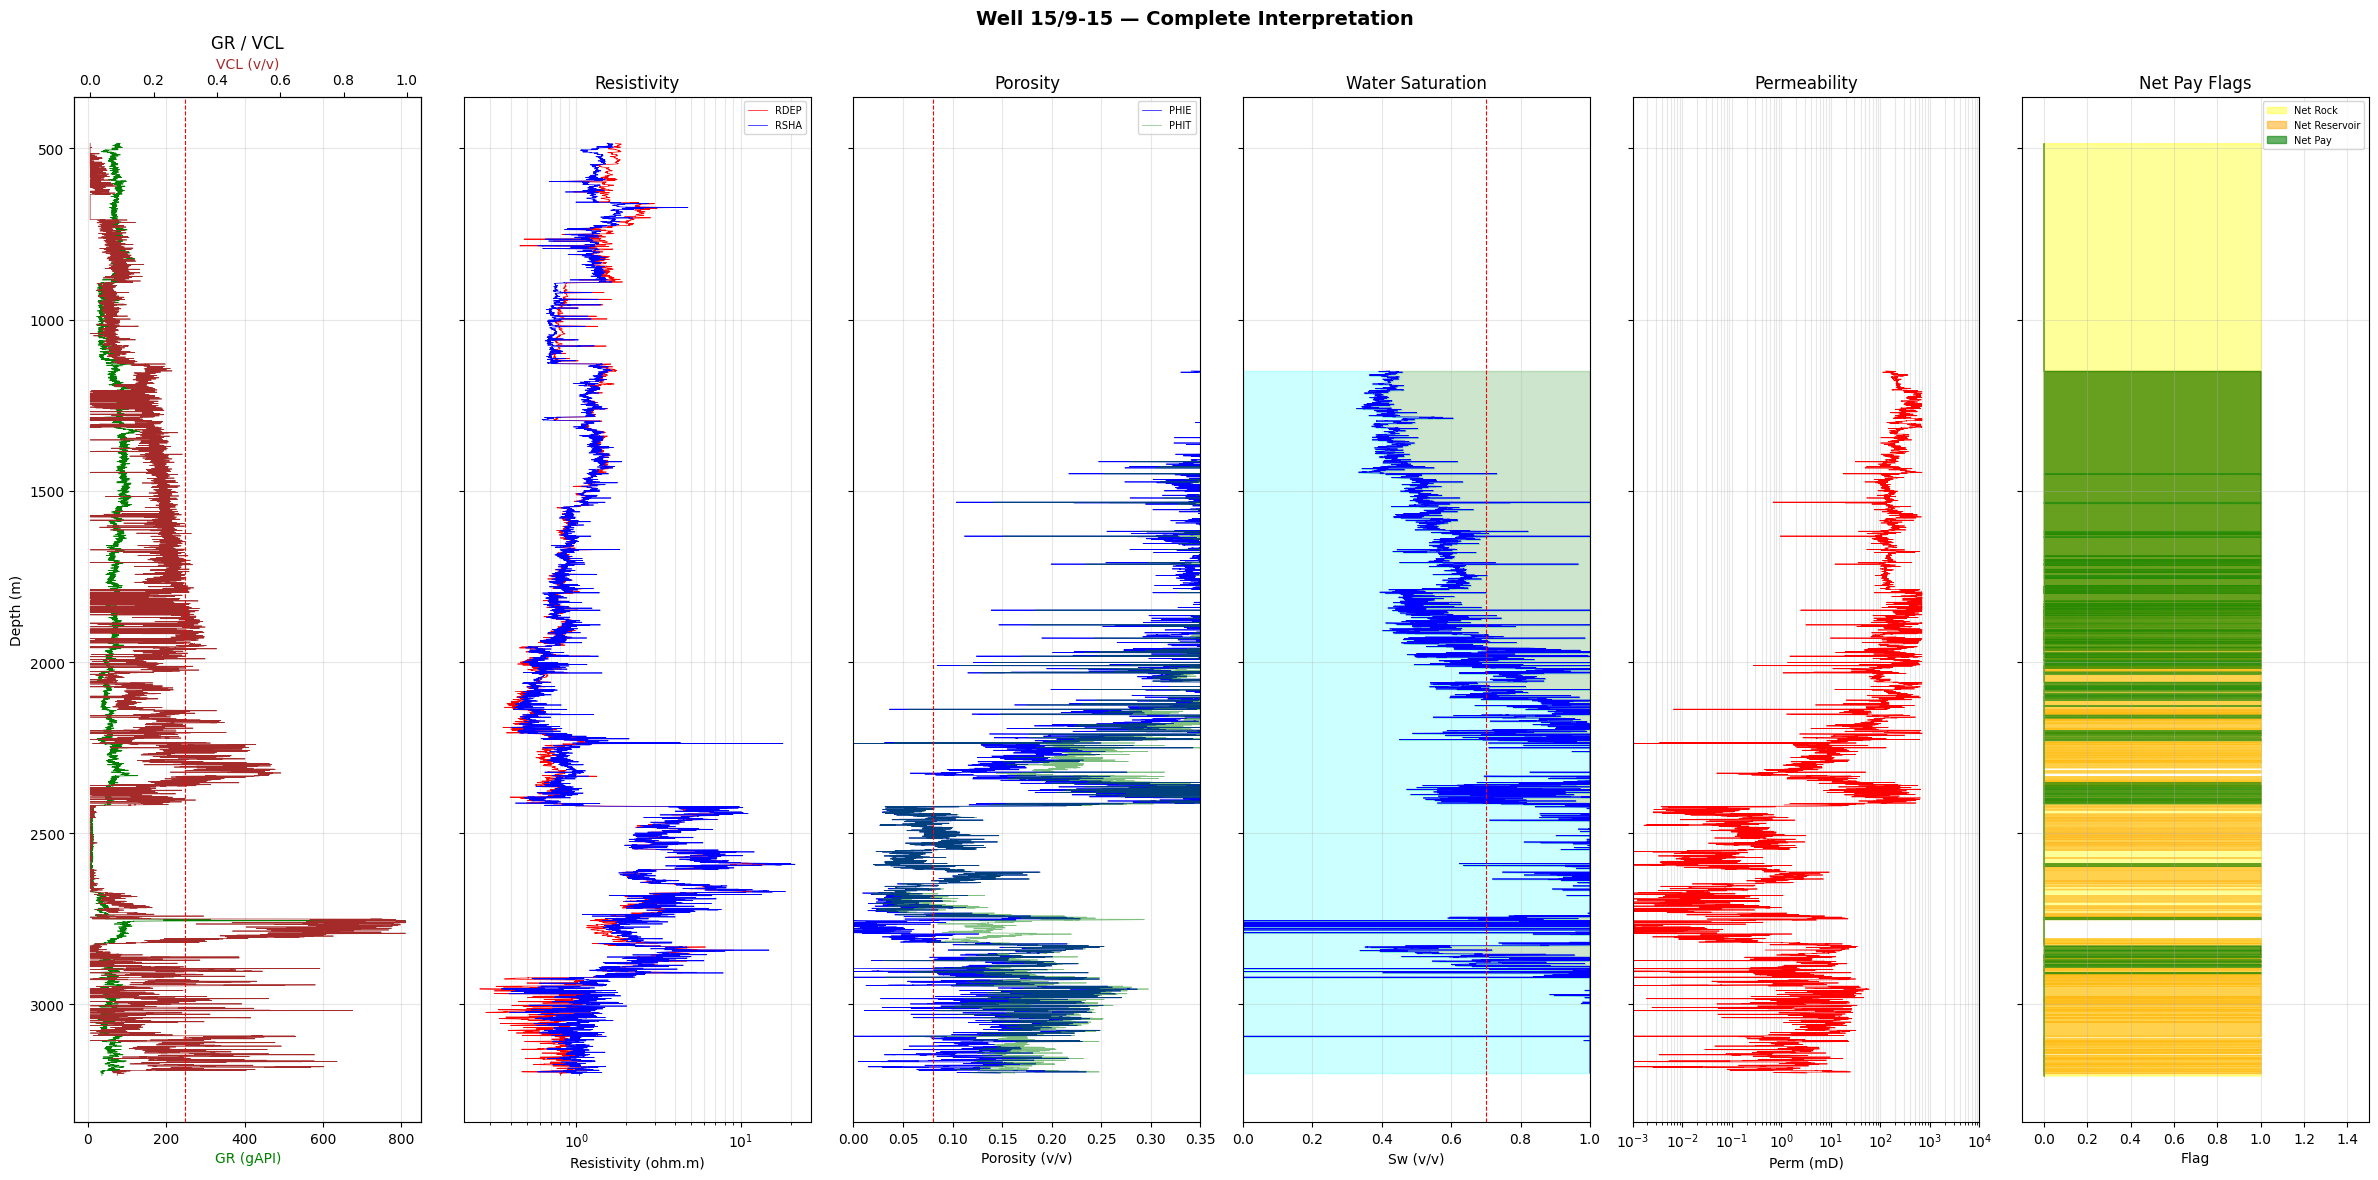

In [19]:
# Interpretation composite plot
fig, axes = plt.subplots(1, 6, figsize=(24, 12), sharey=True)

# Track 1: GR + VCL
ax = axes[0]
ax.plot(well["GR"].data, depth, 'g', linewidth=0.5, label='GR')
ax2 = ax.twiny()
ax2.plot(well["VCL"].data, depth, 'brown', linewidth=0.5, label='VCL')
ax2.axvline(0.3, color='red', linestyle='--', linewidth=0.8)
ax.set_xlabel("GR (gAPI)", color='g')
ax2.set_xlabel("VCL (v/v)", color='brown')
ax.set_ylabel("Depth (m)")
ax.set_title("GR / VCL")
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

# Track 2: Resistivity
ax = axes[1]
ax.semilogx(well["RDEP"].data, depth, 'r', linewidth=0.5, label='RDEP')
ax.semilogx(well["RSHA"].data, depth, 'b', linewidth=0.5, label='RSHA')
ax.set_xlabel("Resistivity (ohm.m)")
ax.set_title("Resistivity")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3, which='both')

# Track 3: Porosity
ax = axes[2]
ax.plot(well["PHIE"].data, depth, 'b', linewidth=0.5, label='PHIE')
ax.plot(well["PHIT"].data, depth, 'g', linewidth=0.5, alpha=0.5, label='PHIT')
ax.axvline(0.08, color='red', linestyle='--', linewidth=0.8)
ax.set_xlabel("Porosity (v/v)")
ax.set_xlim(0, 0.35)
ax.set_title("Porosity")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# Track 4: Sw
ax = axes[3]
ax.plot(well["SW"].data, depth, 'b', linewidth=0.5)
ax.fill_betweenx(depth, well["SW"].data, 1, color='green', alpha=0.2)
ax.fill_betweenx(depth, 0, well["SW"].data, color='cyan', alpha=0.2)
ax.axvline(0.7, color='red', linestyle='--', linewidth=0.8)
ax.set_xlabel("Sw (v/v)")
ax.set_xlim(0, 1)
ax.set_title("Water Saturation")
ax.grid(True, alpha=0.3)

# Track 5: Permeability
ax = axes[4]
ax.semilogx(well["PERM"].data, depth, 'r', linewidth=0.5)
ax.set_xlabel("Perm (mD)")
ax.set_xlim(0.001, 10000)
ax.set_title("Permeability")
ax.grid(True, alpha=0.3, which='both')

# Track 6: Net Pay flags
ax = axes[5]
net_pay_flag = well["NET_PAY"].data
net_res_flag = well["NET_RES"].data
net_rock_flag = well["NET_ROCK"].data
ax.fill_betweenx(depth, 0, net_rock_flag, color='yellow', alpha=0.4, label='Net Rock')
ax.fill_betweenx(depth, 0, net_res_flag, color='orange', alpha=0.5, label='Net Reservoir')
ax.fill_betweenx(depth, 0, net_pay_flag, color='green', alpha=0.6, label='Net Pay')
ax.set_xlabel("Flag")
ax.set_xlim(-0.1, 1.5)
ax.set_title("Net Pay Flags")
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

fig.suptitle(f"Well {well.name} — Complete Interpretation", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 9. Formation-Level Interval Analysis

Now we use the **formation module** to compute per-formation summaries. This is where we combine:
- NPD formation tops (loaded from Excel)
- The computed curves (VCL, PHIE, SW, PERM, NET_PAY)
- The `IntervalAnalyzer` to get net pay, NTG, averages per formation

In [20]:
from petrophys.formation import (
    IntervalKind, Interval, Formation, Zone, SubZone, ManualInterval,
    FormationTops, IntervalAnalyzer, IntervalSummary
)

# Build Formation objects from the NPD tops we already loaded for 15/9-15
# NPD tops give us TOP_MD for each formation — we need to derive bottom depths
# Bottom of one formation = Top of next formation

tops_sorted = tops_15_9.sort_values('TOP_MD').reset_index(drop=True)
print("NPD Formation Tops for well 15_9-15:")
print(tops_sorted[['FORMATION_TOP', 'TOP_MD']].to_string(index=False))

# Create Formation intervals (each formation's bottom = next formation's top)
formation_list = []
for i in range(len(tops_sorted)):
    fm_name = tops_sorted.iloc[i]['FORMATION_TOP']
    top_md = tops_sorted.iloc[i]['TOP_MD']
    
    if i < len(tops_sorted) - 1:
        bot_md = tops_sorted.iloc[i + 1]['TOP_MD']
    else:
        bot_md = well.bottom  # Last formation extends to TD
    
    # Only include formations within well depth range
    if bot_md > well.top and top_md < well.bottom:
        top_md = max(top_md, well.top)
        bot_md = min(bot_md, well.bottom)
        formation_list.append(Formation(
            name=fm_name.replace(' Top', ''),
            top_depth=top_md,
            bottom_depth=bot_md,
        ))

print(f"\nCreated {len(formation_list)} Formation intervals within well range")
for fm in formation_list:
    print(f"  {fm.name:<30s}  {fm.top_depth:>8.1f} - {fm.bottom_depth:>8.1f} m  "
          f"(thickness: {fm.thickness:.1f} m)")

NPD Formation Tops for well 15_9-15:
       FORMATION_TOP  TOP_MD
    NORDLAND GP. Top   108.0
      Utsira Fm. Top   884.0
   HORDALAND GP. Top  1129.0
       Frigg Fm. Top  2027.0
    ROGALAND GP. Top  2208.0
      Balder Fm. Top  2208.0
        Sele Fm. Top  2243.0
       Lista Fm. Top  2332.0
    SHETLAND GP. Top  2418.0
         Tor Fm. Top  2418.0
         Hod Fm. Top  2606.0
    Blodoeks Fm. Top  2672.0
CROMER KNOLL GP. Top  2719.0
     Draupne Fm. Top  2751.0
      VIKING GP. Top  2751.0
     Heather Fm. Top  2806.0
       HEGRE GP. Top  2821.0
   Skagerrak Fm. Top  2821.0

Created 18 Formation intervals within well range
  NORDLAND GP.                       485.0 -    884.0 m  (thickness: 399.0 m)
  Utsira Fm.                         884.0 -   1129.0 m  (thickness: 245.0 m)
  HORDALAND GP.                     1129.0 -   2027.0 m  (thickness: 898.0 m)
  Frigg Fm.                         2027.0 -   2208.0 m  (thickness: 181.0 m)
  ROGALAND GP.                      2208.0 -   220

In [21]:
# --- Using FormationTops collection ---
# You can also load tops into a FormationTops collection for validation and querying

tops_collection = FormationTops(formation_list)

print(f"FormationTops collection: {len(tops_collection)} intervals")
print(f"Names: {tops_collection.names}")

# Validate for overlaps
issues = tops_collection.validate()
if issues:
    print(f"\nValidation issues: {issues}")
else:
    print("\nNo validation issues found!")

# Query: which formation is at 2500m?
at_2500 = tops_collection.get_at_depth(2500)
print(f"\nFormations at 2500m: {[iv.name for iv in at_2500]}")

# Query: formations in depth range
in_range = tops_collection.get_in_range(2200, 2800)
print(f"Formations in 2200-2800m: {[iv.name for iv in in_range]}")

FormationTops collection: 18 intervals
Names: ['NORDLAND GP.', 'Utsira Fm.', 'HORDALAND GP.', 'Frigg Fm.', 'ROGALAND GP.', 'Balder Fm.', 'Sele Fm.', 'Lista Fm.', 'SHETLAND GP.', 'Tor Fm.', 'Hod Fm.', 'Blodoeks Fm.', 'CROMER KNOLL GP.', 'Draupne Fm.', 'VIKING GP.', 'Heather Fm.', 'HEGRE GP.', 'Skagerrak Fm.']

No validation issues found!

Formations at 2500m: ['Tor Fm.']
Formations in 2200-2800m: ['Frigg Fm.', 'ROGALAND GP.', 'Balder Fm.', 'Sele Fm.', 'Lista Fm.', 'SHETLAND GP.', 'Tor Fm.', 'Hod Fm.', 'Blodoeks Fm.', 'CROMER KNOLL GP.', 'Draupne Fm.', 'VIKING GP.']


In [22]:
# --- IntervalAnalyzer: compute per-formation summaries ---

analyzer = IntervalAnalyzer(well)

# Analyze all formations at once
summaries = analyzer.analyze_all(tops_collection, clip_to_well=True)

# Print formatted report
IntervalAnalyzer.print_report(summaries)


INTERVAL ANALYSIS REPORT
Name                           Top      Bot   Gross   NtPay    NTG   PHIE     Sw    VCL     Perm
-----------------------------------------------------------------------------------------------
NORDLAND GP.                 485.0    884.0   399.0     0.0   0.0%    -      -      -       -   
Utsira Fm.                   884.0   1129.0   245.0     0.0   0.0%    -      -      -       -   
HORDALAND GP.               1129.0   2027.0   898.0   765.7  85.3%  0.388  0.502  0.200   218.00
Frigg Fm.                   2027.0   2208.0   181.0    36.7  20.3%  0.428  0.632  0.130   341.92
ROGALAND GP.                2208.0   2208.0     0.0     0.0   0.0%    -      -      -       -   
Balder Fm.                  2208.0   2243.0    35.0     3.8  10.9%  0.423  0.566  0.067   305.46
Sele Fm.                    2243.0   2332.0    89.0     0.0   0.0%    -      -      -       -   
Lista Fm.                   2332.0   2418.0    86.0    26.4  30.6%  0.392  0.615  0.127   228.96
SHETL

In [23]:
# Export to DataFrame for further analysis
summary_df = IntervalAnalyzer.to_dataframe(summaries)
print("Formation Summary DataFrame:")
summary_df[['Name', 'Top', 'Bottom', 'Gross', 'Net Pay', 'NTG', 
            'Avg PHIE', 'Avg Sw', 'Avg VCL', 'Data Coverage %']]

Formation Summary DataFrame:


,Name,Top,Bottom,Gross,Net Pay,NTG,Avg PHIE,Avg Sw,Avg VCL,Data Coverage %
0,NORDLAND GP.,485.028839,884.000000,398.971161,0.000000,0.000000,NaN,NaN,NaN,100.000000
1,Utsira Fm.,884.000000,1129.000000,245.000000,0.000000,0.000000,NaN,NaN,NaN,100.000000
2,HORDALAND GP.,1129.000000,2027.000000,898.000000,765.679939,0.852650,0.387745,0.501916,0.200376,100.000000
3,Frigg Fm.,2027.000000,2208.000000,181.000000,36.714856,0.202845,0.427804,0.631512,0.130278,100.000000
4,ROGALAND GP.,2208.000000,2208.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000
5,Balder Fm.,2208.000000,2243.000000,35.000000,3.808595,0.108817,0.423026,0.566362,0.066773,100.000000
6,Sele Fm.,2243.000000,2332.000000,89.000000,0.000000,0.000000,NaN,NaN,NaN,100.000000
7,Lista Fm.,2332.000000,2418.000000,86.000000,26.355477,0.306459,0.391664,0.615331,0.126609,100.000000
8,SHETLAND GP.,2418.000000,2418.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000
9,Tor Fm.,2418.000000,2606.000000,188.000000,0.457031,0.002431,0.111008,0.648141,0.000000,100.000000


In [24]:
# --- Analyze a single specific interval (ManualInterval) ---
# Useful when you want to focus on a specific depth range

target_zone = ManualInterval(
    name="Reservoir Target (2700-2820m)",
    top_depth=2700,
    bottom_depth=2820,
)

single_summary = analyzer.analyze(target_zone)
zs = single_summary.zone_summary

print(f"Zone: {single_summary.interval.name}")
print(f"  Gross thickness: {zs.gross_thickness:.1f} m")
print(f"  Net Pay:         {zs.net_pay:.1f} m")
print(f"  NTG:             {zs.ntg:.1%}")
print(f"  Avg PHIE:        {zs.avg_phie:.3f}")
print(f"  Avg Sw:          {zs.avg_sw:.3f}")
print(f"  Avg VCL:         {zs.avg_vcl:.3f}")
print(f"  Avg Perm:        {zs.avg_perm:.2f} mD")
print(f"  HCPV:            {zs.hcpv:.4f}")
print(f"  Data Coverage:   {single_summary.data_coverage_pct:.1f}%")

Zone: Reservoir Target (2700-2820m)
  Gross thickness: 120.0 m
  Net Pay:         1.5 m
  NTG:             1.3%
  Avg PHIE:        0.212
  Avg Sw:          0.639
  Avg VCL:         0.088
  Avg Perm:        15.68 mD
  HCPV:            0.1165
  Data Coverage:   100.0%


In [25]:
# --- Hierarchical Intervals: Formations > Zones > SubZones ---
# You can build a hierarchy for detailed analysis

# Group Formations
shetland_gp = Formation(name="SHETLAND GP.", top_depth=2418, bottom_depth=2719, age="Cretaceous")

# Zones within SHETLAND GP.
tor_zone = Zone(name="Tor Fm.", top_depth=2418, bottom_depth=2606, parent_formation="SHETLAND GP.")
hod_zone = Zone(name="Hod Fm.", top_depth=2606, bottom_depth=2672, parent_formation="SHETLAND GP.")
blodoeks_zone = Zone(name="Blodoeks Fm.", top_depth=2672, bottom_depth=2719, parent_formation="SHETLAND GP.")

# SubZones (synthetic example - divide Tor into upper/lower)
tor_upper = SubZone(name="Tor Upper", top_depth=2418, bottom_depth=2512, parent_zone="Tor Fm.")
tor_lower = SubZone(name="Tor Lower", top_depth=2512, bottom_depth=2606, parent_zone="Tor Fm.")

# Analyze each level
hierarchy = [shetland_gp, tor_zone, hod_zone, blodoeks_zone, tor_upper, tor_lower]
hierarchy_summaries = [analyzer.analyze(iv) for iv in hierarchy]

# Report
print("Hierarchical Analysis:")
print(f"{'Level':<12s} {'Name':<20s} {'Gross':>7s} {'NtPay':>7s} {'NTG':>7s} {'PHIE':>7s} {'Sw':>7s}")
print("-" * 70)
for s in hierarchy_summaries:
    zs = s.zone_summary
    kind = s.interval.kind.value
    phie_str = f"{zs.avg_phie:.3f}" if not np.isnan(zs.avg_phie) else "  -  "
    sw_str = f"{zs.avg_sw:.3f}" if not np.isnan(zs.avg_sw) else "  -  "
    print(f"{kind:<12s} {s.interval.name:<20s} {zs.gross_thickness:>7.1f} "
          f"{zs.net_pay:>7.1f} {zs.ntg:>7.1%} {phie_str:>7s} {sw_str:>7s}")

Hierarchical Analysis:
Level        Name                   Gross   NtPay     NTG    PHIE      Sw
----------------------------------------------------------------------
formation    SHETLAND GP.           301.0     0.5    0.2%   0.111   0.648
zone         Tor Fm.                188.0     0.5    0.2%   0.111   0.648
zone         Hod Fm.                 66.0     0.0    0.0%     -       -  
zone         Blodoeks Fm.            47.0     0.0    0.0%     -       -  
sub_zone     Tor Upper               94.0     0.0    0.0%     -       -  
sub_zone     Tor Lower               94.0     0.5    0.5%   0.111   0.648


---
## 10. Full Dynamic Workflow (End-to-End)

The `DynamicWorkflow` automates the entire pipeline. You configure it once, and it:
1. Detects available curves
2. Runs applicable modules in order (temperature, bad hole, VCL, porosity, Sw, perm, net pay)
3. Adds all computed curves to the Well object

This is the **recommended approach** for production use.

In [26]:
from petrophys.workflow import (
    DynamicWorkflow, DynamicWorkflowConfig, run_dynamic_workflow
)

# Load a fresh copy of the well (so we start from raw curves)
well_fresh = read_las(os.path.join(LAS_DIR, "15_9-15.las"))
well_fresh = standardize_curves(well_fresh)

# Configure the workflow with synthetic well parameters
config = DynamicWorkflowConfig(
    # Temperature (synthetic — typical North Sea)
    bht_f=220.0,                 # Bottom Hole Temperature in Fahrenheit
    td_ft=10522.0,               # Total Depth in feet (3207m * 3.281)
    surface_temp_f=68.0,         # Surface temperature
    
    # Mud properties (synthetic — WBM)
    mud_type="WBM",
    rmf_at_meas_temp=0.5,        # Rmf at 75F
    rmf_meas_temp_f=75.0,
    
    # Formation water (synthetic)
    rw=0.04,                     # Rw at formation temperature
    
    # Matrix (North Sea clastics)
    matrix_type="sandstone",
    lithology="clastic",
    
    # Archie parameters
    a=1.0, m=2.0, n=2.0,
    
    # Cutoffs
    vcl_cutoff=0.30,
    phie_cutoff=0.08,
    sw_cutoff=0.70,
    
    # GR method
    gr_method="larionov_tertiary",
    
    # Permeability
    perm_method="timur",
)

print("Running Dynamic Workflow...")
result = DynamicWorkflow(config).run(well_fresh)

print(f"\nWorkflow completed: {'SUCCESS' if result.success else 'FAILED'}")
print(f"\nSteps executed ({len(result.steps_executed)}):")
for step in result.steps_executed:
    status = "OK" if step.success else f"FAIL: {step.message}"
    print(f"  {step.step:<20s} {status}")

print(f"\nSteps skipped ({len(result.steps_skipped)}):")
for s in result.steps_skipped:
    print(f"  {s}")

if result.warnings:
    print(f"\nWarnings:")
    for w in result.warnings:
        print(f"  {w}")

print(f"\nComputed values:")
print(f"  Rw: {result.rw_computed}")
print(f"  Rmf: {result.rmf_computed}")
print(f"  Rcl: {result.rcl_computed}")

print(f"\nFinal curves on well: {well_fresh.curves}")

Running Dynamic Workflow...

Workflow completed: SUCCESS

Steps executed (15):
  temperature          FAIL: TemperatureProfile.from_bht() got an unexpected keyword argument 'temp_unit'
  bad_hole             FAIL: generate_bad_hole_flags() got an unexpected keyword argument 'cali'
  vclay                OK
  rcl                  OK
  lithology            OK
  rmf                  FAIL: RmfModule.calculate() got an unexpected keyword argument 'temp_surface'
  rw                   OK
  invasion             OK
  hc_correction        OK
  porosity             OK
  saturation           OK
  permeability         OK
  rock_quality         OK
  bvw                  OK
  net_pay              OK

Steps skipped (1):
  mhi

Warnings:
  temperature: TemperatureProfile.from_bht() got an unexpected keyword argument 'temp_unit'
  bad_hole: generate_bad_hole_flags() got an unexpected keyword argument 'cali'
  rmf: RmfModule.calculate() got an unexpected keyword argument 'temp_surface'

Computed values:

In [27]:
# --- One-liner convenience function ---
# run_dynamic_workflow(well, **kwargs) creates the config from keyword args

well_oneliner = read_las(os.path.join(LAS_DIR, "15_9-15.las"))
well_oneliner = standardize_curves(well_oneliner)

result2 = run_dynamic_workflow(
    well_oneliner,
    bht_f=220.0,
    td_ft=10522.0,
    rw=0.04,
    rmf_at_meas_temp=0.5,
    lithology="clastic",
    gr_method="larionov_tertiary",
)

print(f"One-liner result: {len(result2.steps_executed)} steps executed")
print(f"Curves: {well_oneliner.curves}")

One-liner result: 15 steps executed
Curves: ['LITHOLOGY_GEOLINK', 'CALI', 'BS', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DT', 'RDEP', 'SP', 'RSHA', 'RMED', 'VCL', 'VCLGR', 'VCLSP', 'VCLND', 'VQUAR', 'VCALC', 'VDOLO', 'LITHO', 'INVASION_RATIO', 'NPHI_HC', 'RHOB_HC', 'PHID', 'PHIT', 'PHIE', 'PHIS', 'PHI_SEC', 'SW', 'PERM', 'IMPERM_FLAG', 'RQI', 'PHI_Z', 'FZI', 'BVW', 'NET_ROCK', 'NET_RES', 'NET_PAY']


---
## 11. Multi-Well Comparison

Process a second well (16/10-1) through the same workflow and compare formation-level results.

In [28]:
# Process well 16/10-1 through the full workflow
well2 = read_las(os.path.join(LAS_DIR, "16_10-1.las"))
well2 = standardize_curves(well2)

result_w2 = run_dynamic_workflow(
    well2,
    bht_f=200.0,                  # Slightly cooler well
    td_ft=10354.0,                # 3157m * 3.281
    rw=0.04,
    rmf_at_meas_temp=0.5,
    lithology="clastic",
    gr_method="larionov_tertiary",
)

print(f"Well 2 ({well2.name}): {len(result_w2.steps_executed)} steps executed")
print(f"Steps: {[s.step for s in result_w2.steps_executed if s.success]}")
print(f"Curves: {well2.curves}")

Well 2 (16/10-1 Alpha): 15 steps executed
Steps: ['vclay', 'rcl', 'lithology', 'rw', 'invasion', 'hc_correction', 'porosity', 'saturation', 'permeability', 'rock_quality', 'bvw', 'net_pay']
Curves: ['LITHOLOGY_GEOLINK', 'CALI', 'BS', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'RDEP', 'SP', 'RSHA', 'RXO', 'RMED', 'VCL', 'VCLGR', 'VCLSP', 'VCLND', 'VQUAR', 'VCALC', 'VDOLO', 'LITHO', 'INVASION_RATIO', 'NPHI_HC', 'RHOB_HC', 'PHID', 'PHIT', 'PHIE', 'PHIS', 'PHI_SEC', 'SW', 'PERM', 'IMPERM_FLAG', 'RQI', 'PHI_Z', 'FZI', 'BVW', 'NET_ROCK', 'NET_RES', 'NET_PAY']


In [29]:
# Load tops for well 16/10-1 and run formation analysis
_, _, tops_16_10 = link_lithology_and_tops(
    os.path.join(LAS_DIR, "16_10-1.las"), LITHO_FILE, TOPS_FILE
)

# Build formation intervals for well 2
tops2_sorted = tops_16_10.sort_values('TOP_MD').reset_index(drop=True)
fm_list_w2 = []
for i in range(len(tops2_sorted)):
    fm_name = tops2_sorted.iloc[i]['FORMATION_TOP']
    top_md = tops2_sorted.iloc[i]['TOP_MD']
    bot_md = tops2_sorted.iloc[i + 1]['TOP_MD'] if i < len(tops2_sorted) - 1 else well2.bottom
    if bot_md > well2.top and top_md < well2.bottom:
        top_md = max(top_md, well2.top)
        bot_md = min(bot_md, well2.bottom)
        fm_list_w2.append(Formation(name=fm_name.replace(' Top', ''), top_depth=top_md, bottom_depth=bot_md))

analyzer2 = IntervalAnalyzer(well2)
summaries_w2 = analyzer2.analyze_all(FormationTops(fm_list_w2))

print(f"\n{'='*60}")
print(f"Well: {well2.name}")
print(f"{'='*60}")
IntervalAnalyzer.print_report(summaries_w2)

Found 24 formation tops for well '16_10-1'

Well: 16/10-1 Alpha

INTERVAL ANALYSIS REPORT
Name                           Top      Bot   Gross   NtPay    NTG   PHIE     Sw    VCL     Perm
-----------------------------------------------------------------------------------------------
NORDLAND GP.                 439.1   1024.0   584.9     0.0   0.0%    -      -      -       -   
Utsira Fm.                  1024.0   1197.0   173.0     0.0   0.0%    -      -      -       -   
HORDALAND GP.               1197.0   2120.0   923.0    95.7  10.4%  0.391  0.580  0.136   430.28
ROGALAND GP.                2120.0   2120.0     0.0     0.0   0.0%    -      -      -       -   
Balder Fm.                  2120.0   2136.0    16.0     0.0   0.0%    -      -      -       -   
Sele Fm.                    2136.0   2189.0    53.0     0.0   0.0%    -      -      -       -   
Lista Fm.                   2189.0   2245.0    56.0     0.0   0.0%    -      -      -       -   
Vaale Fm.                   2245.0   2

Common formations: {'Balder Fm.', 'Hod Fm.', 'ROGALAND GP.', 'HORDALAND GP.', 'Blodoeks Fm.', 'VIKING GP.', 'Tor Fm.', 'NORDLAND GP.', 'Utsira Fm.', 'Sele Fm.', 'CROMER KNOLL GP.', 'Lista Fm.', 'SHETLAND GP.', 'Skagerrak Fm.', 'Draupne Fm.', 'Heather Fm.'}

Multi-Well Formation Comparison:
         Well             Name      Gross    Net Pay      NTG  Avg PHIE   Avg Sw
      15/9-15       Balder Fm.  35.000000   3.808595 0.108817  0.423026 0.566362
16/10-1 Alpha       Balder Fm.  16.000000   0.000000 0.000000       NaN      NaN
      15/9-15     Blodoeks Fm.  47.000000   0.000000 0.000000       NaN      NaN
16/10-1 Alpha     Blodoeks Fm.   8.000000   0.000000 0.000000       NaN      NaN
      15/9-15 CROMER KNOLL GP.  32.000000   1.523438 0.047607  0.211840 0.639157
16/10-1 Alpha CROMER KNOLL GP.  13.000000   0.000000 0.000000       NaN      NaN
      15/9-15      Draupne Fm.   0.000000   0.000000 0.000000       NaN      NaN
16/10-1 Alpha      Draupne Fm.  59.000000   0.000000 0.000000

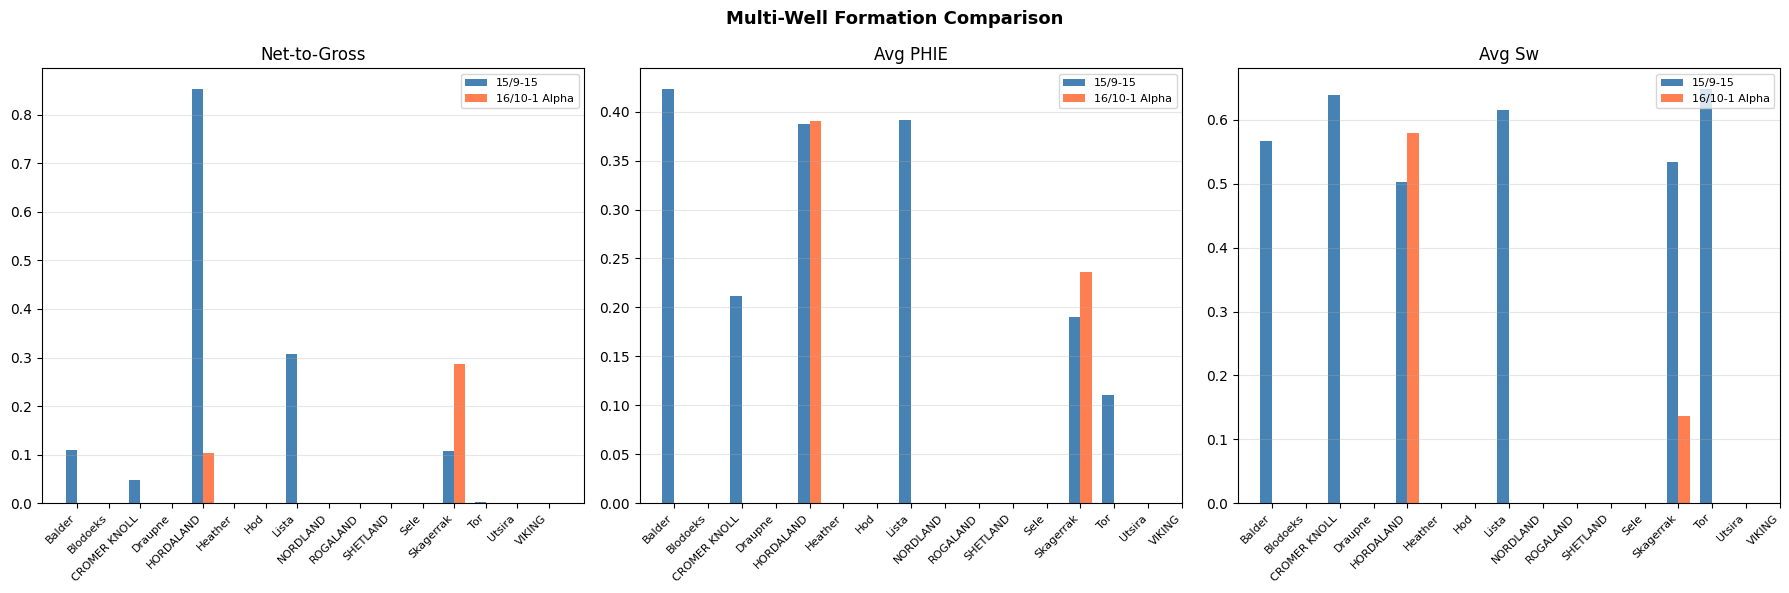

In [30]:
# Compare common formations between wells
df1 = IntervalAnalyzer.to_dataframe(summaries)
df1['Well'] = well.name
df2 = IntervalAnalyzer.to_dataframe(summaries_w2)
df2['Well'] = well2.name

# Find formations present in both wells
common_fms = set(df1['Name']) & set(df2['Name'])
print(f"Common formations: {common_fms}")

if common_fms:
    # Compare NTG and average properties for common formations
    combined = pd.concat([
        df1[df1['Name'].isin(common_fms)][['Well', 'Name', 'Gross', 'Net Pay', 'NTG', 'Avg PHIE', 'Avg Sw']],
        df2[df2['Name'].isin(common_fms)][['Well', 'Name', 'Gross', 'Net Pay', 'NTG', 'Avg PHIE', 'Avg Sw']]
    ]).sort_values(['Name', 'Well'])
    
    print("\nMulti-Well Formation Comparison:")
    print(combined.to_string(index=False))
    
    # Bar chart comparison
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    common_list = sorted(common_fms)
    x = np.arange(len(common_list))
    width = 0.35
    
    for idx, (metric, title) in enumerate([('NTG', 'Net-to-Gross'), ('Avg PHIE', 'Avg PHIE'), ('Avg Sw', 'Avg Sw')]):
        ax = axes[idx]
        vals1 = [df1[df1['Name'] == fm][metric].values[0] if fm in df1['Name'].values else 0 for fm in common_list]
        vals2 = [df2[df2['Name'] == fm][metric].values[0] if fm in df2['Name'].values else 0 for fm in common_list]
        
        bars1 = ax.bar(x - width/2, vals1, width, label=well.name, color='steelblue')
        bars2 = ax.bar(x + width/2, vals2, width, label=well2.name, color='coral')
        ax.set_xticks(x)
        ax.set_xticklabels([fm.replace(' Fm.', '').replace(' GP.', '') for fm in common_list], 
                          rotation=45, ha='right', fontsize=8)
        ax.set_title(title)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, axis='y')
    
    fig.suptitle("Multi-Well Formation Comparison", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## 12. Additional Reservoir Calculations

The library also provides:
- **Bulk Volume Water (BVW)**: PHIE * Sw — indicates irreducible water
- **Rock Quality Index (RQI)**: sqrt(k/phi) — flow unit indicator
- **Flow Zone Indicator (FZI)**: RQI / phi_z — hydraulic unit classification

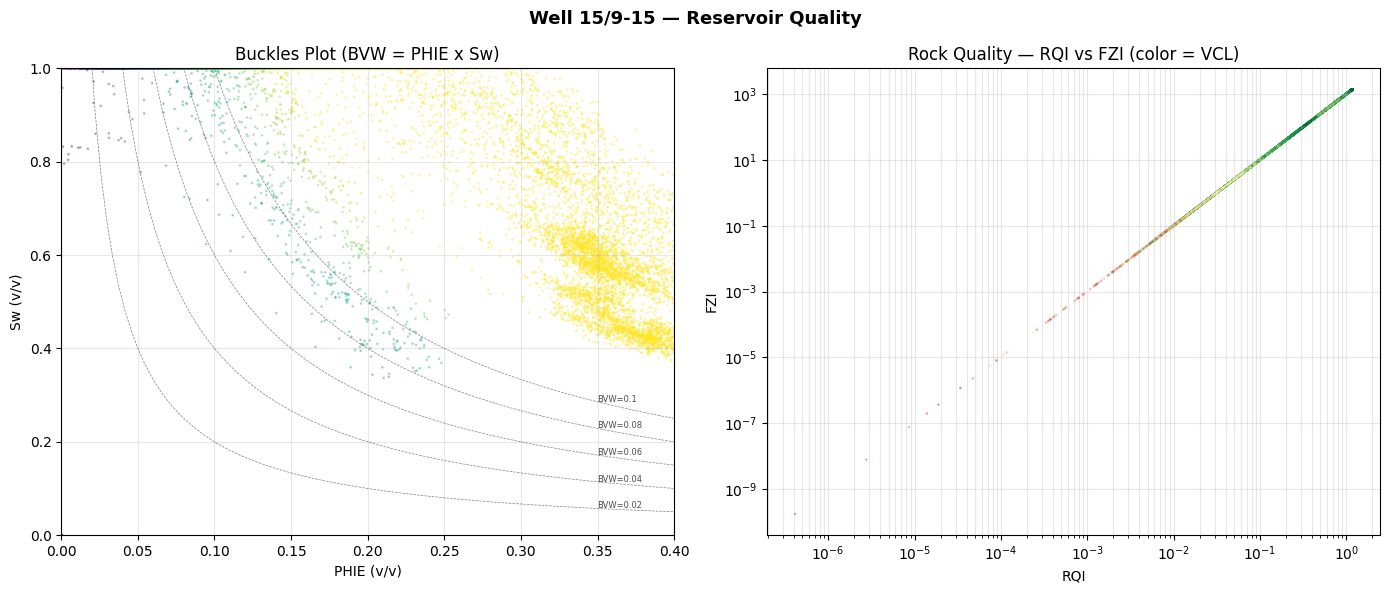

In [31]:
from petrophys.reservoir import calculate_bvw, calculate_rock_quality, calculate_rqi, calculate_fzi

# BVW
bvw = calculate_bvw(well["PHIE"].data, well["SW"].data)
well.add_curve("BVW", bvw, "v/v", "Bulk Volume Water")

# Rock Quality
rqi = calculate_rqi(well["PERM"].data, well["PHIE"].data)
well.add_curve("RQI", rqi, "", "Rock Quality Index")

fzi = calculate_fzi(well["PERM"].data, well["PHIE"].data)
well.add_curve("FZI", fzi, "", "Flow Zone Indicator")

# BVW plot (classic Buckles plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# BVW vs Depth
ax = axes[0]
valid = ~np.isnan(bvw) & ~np.isnan(well["SW"].data)
ax.scatter(well["PHIE"].data[valid], well["SW"].data[valid], c=bvw[valid], 
           cmap='viridis', s=1, alpha=0.3, vmin=0, vmax=0.15)
# Buckles hyperbolas
for bvw_val in [0.02, 0.04, 0.06, 0.08, 0.10]:
    phi_range = np.linspace(0.01, 0.40, 100)
    sw_buckles = bvw_val / phi_range
    ax.plot(phi_range, sw_buckles, 'k--', linewidth=0.5, alpha=0.5)
    ax.text(0.35, bvw_val/0.35, f'BVW={bvw_val}', fontsize=6, alpha=0.7)
ax.set_xlabel("PHIE (v/v)")
ax.set_ylabel("Sw (v/v)")
ax.set_xlim(0, 0.40)
ax.set_ylim(0, 1)
ax.set_title("Buckles Plot (BVW = PHIE x Sw)")
ax.grid(True, alpha=0.3)

# RQI-FZI plot
ax = axes[1]
valid_rq = ~np.isnan(rqi) & ~np.isnan(fzi) & (rqi > 0) & (fzi > 0)
ax.scatter(rqi[valid_rq], fzi[valid_rq], c=well["VCL"].data[valid_rq], 
           cmap='RdYlGn_r', s=1, alpha=0.3, vmin=0, vmax=1)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel("RQI")
ax.set_ylabel("FZI")
ax.set_title("Rock Quality — RQI vs FZI (color = VCL)")
ax.grid(True, alpha=0.3, which='both')

fig.suptitle(f"Well {well.name} — Reservoir Quality", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 13. Summation Module — Zone Summaries and HCPV

The low-level summation module provides direct access to zone-by-zone calculations without needing the formation module.

In [34]:
from petrophys.summation import (
    calculate_zone_summary, summarize_zones,
    calculate_hcpv, calculate_ooip, calculate_ogip,
    calculate_net_gross
)

# Direct zone summary for a specific depth range
zs = calculate_zone_summary(
    well, 
    top_depth=2750, 
    bottom_depth=2821,
    zone_name="Draupne + Heather"
)

print(f"Zone: {zs.zone_name}")
print(f"  Gross: {zs.gross_thickness:.1f} m")
print(f"  Net Pay: {zs.net_pay:.1f} m")
print(f"  NTG: {zs.ntg:.1%}")
print(f"  Avg PHIE: {zs.avg_phie:.3f}")
print(f"  Avg Sw: {zs.avg_sw:.3f}")
print(f"  HCPV: {zs.hcpv:.4f}")

# Multiple zones at once using summarize_zones
# Note: summarize_zones expects keys "name", "top", "bottom"
zones_spec = [
    {"name": "Balder Fm.", "top": 2208, "bottom": 2243},
    {"name": "Sele Fm.", "top": 2243, "bottom": 2332},
    {"name": "Lista Fm.", "top": 2332, "bottom": 2418},
    {"name": "Tor Fm.", "top": 2418, "bottom": 2606},
    {"name": "Hod Fm.", "top": 2606, "bottom": 2672},
]

multi_summaries = summarize_zones(well, zones_spec)
print(f"\n{'Zone':<20s} {'Gross':>7s} {'NtPay':>7s} {'NTG':>7s} {'PHIE':>7s} {'Sw':>7s}")
print("-" * 55)
for zs in multi_summaries:
    phie_s = f"{zs.avg_phie:.3f}" if not np.isnan(zs.avg_phie) else "  -  "
    sw_s = f"{zs.avg_sw:.3f}" if not np.isnan(zs.avg_sw) else "  -  "
    print(f"{zs.zone_name:<20s} {zs.gross_thickness:>7.1f} {zs.net_pay:>7.1f} "
          f"{zs.ntg:>7.1%} {phie_s:>7s} {sw_s:>7s}")

Zone: Draupne + Heather
  Gross: 71.0 m
  Net Pay: 0.0 m
  NTG: 0.0%
  Avg PHIE: nan
  Avg Sw: nan
  HCPV: nan

Zone                   Gross   NtPay     NTG    PHIE      Sw
-------------------------------------------------------
Balder Fm.              35.0     3.8   10.9%   0.423   0.566
Sele Fm.                89.0     0.0    0.0%     -       -  
Lista Fm.               86.0    26.4   30.6%   0.392   0.615
Tor Fm.                188.0     0.5    0.2%   0.111   0.648
Hod Fm.                 66.0     0.0    0.0%     -       -  


In [36]:
# HCPV and OOIP/OGIP estimation (synthetic area and Bo/Bg)
# These require reservoir engineering parameters

# Synthetic drainage area and formation volume factor
AREA_ACRES = 640          # 1 section = 640 acres
BO = 1.2                  # Oil formation volume factor (rb/stb)
BG = 0.005                # Gas formation volume factor (rb/scf)

# For a specific pay zone
pay_phie = 0.18
pay_sw = 0.35
pay_ntg = 0.65
pay_thickness_ft = 50     # Net pay in feet

# Calculate OOIP (returns a dict)
ooip = calculate_ooip(
    area_acres=AREA_ACRES,
    net_pay_ft=pay_thickness_ft,
    porosity=pay_phie,
    sw=pay_sw,
    bo=BO
)

# Calculate OGIP (returns a dict)
ogip = calculate_ogip(
    area_acres=AREA_ACRES,
    net_pay_ft=pay_thickness_ft,
    porosity=pay_phie,
    sw=pay_sw,
    bg=BG
)

print(f"Volumetric Estimates (synthetic parameters):")
print(f"  Area:          {AREA_ACRES} acres")
print(f"  Net Pay:       {pay_thickness_ft} ft")
print(f"  PHIE:          {pay_phie}")
print(f"  Sw:            {pay_sw}")
print(f"  Bo:            {BO}")
print(f"  OOIP:          {ooip['ooip_stb']:,.0f} STB")
print(f"  OOIP:          {ooip['ooip_mmbbl']:,.2f} MMSTB")
print(f"  Recoverable:   {ooip['recoverable_stb']:,.0f} STB (RF={ooip['recovery_factor']:.0%})")
print(f"  OGIP:          {ogip['ogip_scf']:,.0f} SCF")
print(f"  OGIP:          {ogip['ogip_bcf']:,.2f} BCF")
print(f"  Recoverable:   {ogip['recoverable_bcf']:,.2f} BCF (RF={ogip['recovery_factor']:.0%})")

Volumetric Estimates (synthetic parameters):
  Area:          640 acres
  Net Pay:       50 ft
  PHIE:          0.18
  Sw:            0.35
  Bo:            1.2
  OOIP:          24,206,208 STB
  OOIP:          24.21 MMSTB
  Recoverable:   7,261,862 STB (RF=30%)
  OGIP:          32,617,728,000 SCF
  OGIP:          32.62 BCF
  Recoverable:   22.83 BCF (RF=70%)


---
## 14. Exporting Results

The library supports exporting to LAS, CSV, and Excel formats.

In [37]:
# Export well with all computed curves
print(f"Well has {well.n_curves} curves: {well.curves}")

# Export to DataFrame
result_df = well.to_dataframe()
print(f"\nDataFrame shape: {result_df.shape}")
print(result_df[['DEPTH', 'GR', 'VCL', 'PHIE', 'SW', 'PERM', 'NET_PAY']].describe())

# Export to CSV
# well.to_csv("output/15_9-15_interpreted.csv")

# Export to LAS
# well.to_las("output/15_9-15_interpreted.las")

# Export formation summaries to CSV
# IntervalAnalyzer.to_csv(summaries, "output/15_9-15_formation_summaries.csv")

# Export tops to DataFrame
tops_df_export = tops_collection.to_dataframe()
print(f"\nFormation Tops DataFrame:")
tops_df_export

Well has 30 curves: ['LITHOLOGY_GEOLINK', 'CALI', 'BS', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DT', 'RDEP', 'SP', 'RSHA', 'RMED', 'VCL', 'VCLGR', 'VCLSP', 'VCLND', 'PHID', 'PHIS', 'PHIT', 'PHIE', 'SW', 'PERM', 'NET_ROCK', 'NET_RES', 'NET_PAY', 'BVW', 'RQI', 'FZI']

DataFrame shape: (17864, 31)
              DEPTH            GR           VCL          PHIE            SW  \
count  17864.000000  17864.000000  17864.000000  13453.000000  13453.000000   
mean    1846.189103     58.820248      0.158604      0.257421      0.751937   
std      785.932237     29.617283      0.149481      0.139190      0.240444   
min      485.028839      5.633000      0.000000      0.000000      0.000000   
25%     1165.608978     40.555939      0.048745      0.125079      0.527263   
50%     1846.189026     61.935345      0.140203      0.298634      0.771676   
75%     2526.769348     75.308258      0.232796      0.369035      1.000000   
max     3207.349365    811.000000      0.995671      0.500000      

,name,top_depth,bottom_depth,thickness,kind,lithology,age
0,NORDLAND GP.,485.028839,884.000000,398.971161,formation,,
1,Utsira Fm.,884.000000,1129.000000,245.000000,formation,,
2,HORDALAND GP.,1129.000000,2027.000000,898.000000,formation,,
3,Frigg Fm.,2027.000000,2208.000000,181.000000,formation,,
4,ROGALAND GP.,2208.000000,2208.000000,0.000000,formation,,
5,Balder Fm.,2208.000000,2243.000000,35.000000,formation,,
6,Sele Fm.,2243.000000,2332.000000,89.000000,formation,,
7,Lista Fm.,2332.000000,2418.000000,86.000000,formation,,
8,SHETLAND GP.,2418.000000,2418.000000,0.000000,formation,,
9,Tor Fm.,2418.000000,2606.000000,188.000000,formation,,


---
## 15. Core Data Module — Lab Measurements & Log-Core Calibration

The `petrophys.core` module provides:
- **`CoreData`** — Container for core plug measurements (load from CSV/Excel/DataFrame)
- **`calibrate_porosity`** / **`calibrate_permeability`** — Statistical comparison (R², bias, RMSE)
- **`fit_poro_perm_transform`** / **`apply_poro_perm_transform`** — Derive & apply core-based K(phi) 
- **`correct_porosity_with_grain_density`** — Use core grain density instead of assumed matrix density
- **`estimate_archie_m`** — Back-calculate cementation exponent from core Sw
- **`plot_calibration`** / **`plot_poro_perm`** / **`plot_core_on_logs`** — Visualization

Below we create synthetic core data (in practice, load from your lab CSV) and walk through each function.

In [ ]:
from petrophys.core import (
    CoreData,
    calibrate_porosity, calibrate_permeability,
    fit_poro_perm_transform, apply_poro_perm_transform,
    correct_porosity_with_grain_density,
    estimate_archie_m,
    plot_calibration, plot_poro_perm, plot_core_on_logs,
)

# ============================================================
# 15a. Create synthetic core data (simulating lab results)
# ============================================================
# In practice: CoreData.from_csv("core_lab_results.csv", depth_col="DEPTH", ...)
#              CoreData.from_excel("core_data.xlsx", porosity_col="He_Por", ...)

np.random.seed(42)

core_top, core_bot = 2418.0, 2606.0
core_depths = np.arange(core_top + 1, core_bot, 2.0)  # plug every 2m
n_plugs = len(core_depths)

# Synthetic lab measurements with realistic scatter
log_phie_at_core = np.interp(core_depths, well.depth, well["PHIE"].data)
core_porosity = log_phie_at_core + np.random.normal(0, 0.015, n_plugs)
core_porosity = np.clip(core_porosity, 0.01, 0.40)

core_perm = 10 ** (15 * core_porosity - 1.5 + np.random.normal(0, 0.4, n_plugs))
core_perm = np.clip(core_perm, 0.01, 5000)

core_gd = 2.65 + np.random.normal(0, 0.03, n_plugs)

log_sw_at_core = np.interp(core_depths, well.depth, well["SW"].data)
core_sw = log_sw_at_core + np.random.normal(0, 0.05, n_plugs)
core_sw = np.clip(core_sw, 0.05, 1.0)

# Build CoreData object from a DataFrame (most common real-world workflow)
core_df = pd.DataFrame({
    "DEPTH": core_depths,
    "CPOR": core_porosity,
    "CPERM": core_perm,
    "CGD": core_gd,
    "CSW": core_sw,
})

core = CoreData.from_dataframe(
    core_df,
    depth_col="DEPTH",
    porosity_col="CPOR",
    perm_col="CPERM",
    gd_col="CGD",
    sw_col="CSW",
)

print(core)
print(f"\nCore DataFrame preview:")
core.to_dataframe().describe().round(3)

In [ ]:
# ============================================================
# 15b. Porosity & Permeability Calibration
# ============================================================

# Calibrate porosity: core vs log PHIE
phi_cal = calibrate_porosity(well, core, log_curve="PHIE")
print(f"Porosity calibration: R²={phi_cal.r_squared:.3f}, Bias={phi_cal.bias:.4f}, RMSE={phi_cal.rmse:.4f}")

# Calibrate permeability: core vs log PERM (in log10 space)
perm_cal = calibrate_permeability(well, core, log_curve="PERM", log_scale=True)
print(f"Perm calibration (log10): R²={perm_cal.r_squared:.3f}, Bias={perm_cal.bias:.4f}, RMSE={perm_cal.rmse:.4f}")

# Plot both calibrations side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_calibration(phi_cal, ax=axes[0], title="Core vs Log Porosity")
axes[0].set_xlabel("Core Porosity (v/v)")
axes[0].set_ylabel("Log PHIE (v/v)")

plot_calibration(perm_cal, ax=axes[1], title="Core vs Log Permeability (log₁₀)")
axes[1].set_xlabel("Core log₁₀(K)")
axes[1].set_ylabel("Log log₁₀(K)")

fig.suptitle(f"Well {well.name} — Core Calibration (Tor Fm.)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 15c. Poro-Perm Transform — fit from core, apply to logs
# ============================================================

# Fit: log10(K) = A * PHI + B
transform = fit_poro_perm_transform(core)
print(transform)

# Plot poro-perm crossplot with the fitted line
fig, ax = plot_poro_perm(core, transform=transform)
ax.set_title(f"Core Poro-Perm — {well.name} (Tor Fm.)")
plt.show()

# Apply the transform to the full well (replaces generic Timur equation)
perm_core = apply_poro_perm_transform(well, transform, porosity_curve="PHIE", output_curve="PERM_CORE")
print(f"\nPERM_CORE curve added to well. Range: {np.nanmin(perm_core):.3f} - {np.nanmax(perm_core):.1f} mD")

In [ ]:
# ============================================================
# 15d. Grain Density Correction — better density porosity
# ============================================================

phid_corrected = correct_porosity_with_grain_density(
    well, core,
    rhob_curve="RHOB",
    rho_fluid=1.0,
    default_rho_ma=2.65,
    output_curve="PHID_CORE",
)
print(f"PHID_CORE curve added. Range: {np.nanmin(phid_corrected):.3f} - {np.nanmax(phid_corrected):.3f}")

In [ ]:
# ============================================================
# 15e. Archie m Estimation from Core Sw
# ============================================================

m_result = estimate_archie_m(
    well, core,
    rw=RW,              # 0.04 ohm.m
    rt_curve="RDEP",
    a=A, n=N,           # a=1.0, n=2.0
)

print(f"Archie cementation exponent from core:")
print(f"  m mean:   {m_result['m_mean']:.2f}")
print(f"  m median: {m_result['m_median']:.2f}")
print(f"  m std:    {m_result['m_std']:.2f}")
print(f"  n_points: {m_result['n_points']}")

# Histogram
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(m_result['m_values'], bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax.axvline(m_result['m_median'], color='red', linestyle='--', linewidth=2,
           label=f"Median m = {m_result['m_median']:.2f}")
ax.axvline(2.0, color='gray', linestyle=':', linewidth=1.5, label='Assumed m = 2.0')
ax.set_xlabel("Back-Calculated m")
ax.set_ylabel("Count")
ax.set_title(f"Cementation Exponent from Core Sw — {well.name}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 15f. Core on Logs — overlay core points on log tracks
# ============================================================

fig, axes = plot_core_on_logs(
    well, core,
    curves=["GR", "PHIE", "PERM", "SW"],
    depth_range=(core.top - 30, core.bottom + 30),
    figsize=(18, 12),
)
plt.show()

---
## 15. Sensitivity Analysis — Varying Cutoffs and Parameters

A common workflow is to test how different cutoff values affect net pay. Here we sweep VCL and Sw cutoffs and observe the impact on NTG for a target formation.

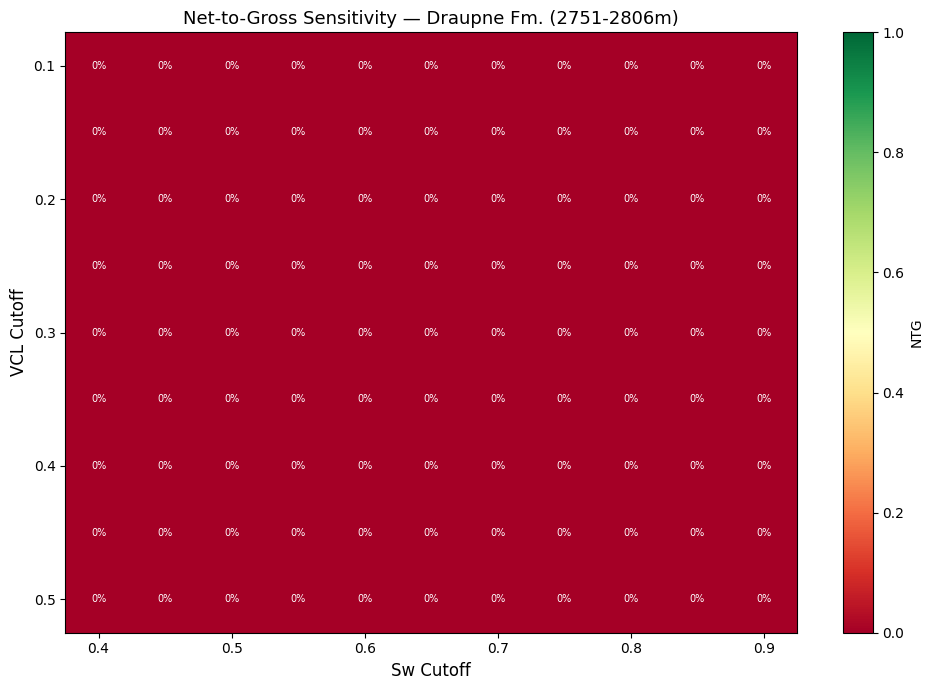

In [38]:
# Sensitivity: Vary Sw cutoff from 0.4 to 0.9 and VCL cutoff from 0.1 to 0.5
# Measure NTG for the Draupne Fm. interval (2751-2806m)

target_fm = Formation(name="Draupne Fm.", top_depth=2751, bottom_depth=2806)

sw_cutoffs = np.arange(0.40, 0.95, 0.05)
vcl_cutoffs = np.arange(0.10, 0.55, 0.05)

# Store NTG for each combination
ntg_matrix = np.zeros((len(vcl_cutoffs), len(sw_cutoffs)))

for i, vc in enumerate(vcl_cutoffs):
    for j, sc in enumerate(sw_cutoffs):
        # Re-compute net pay with new cutoffs
        temp_well = read_las(os.path.join(LAS_DIR, "15_9-15.las"))
        temp_well = standardize_curves(temp_well)
        run_dynamic_workflow(temp_well, bht_f=220, td_ft=10522, rw=0.04,
                           rmf_at_meas_temp=0.5, lithology="clastic",
                           vcl_cutoff=vc, sw_cutoff=sc, phie_cutoff=0.08)
        
        temp_analyzer = IntervalAnalyzer(temp_well)
        s = temp_analyzer.analyze(target_fm)
        ntg_matrix[i, j] = s.zone_summary.ntg

# Heatmap
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(ntg_matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1,
               extent=[sw_cutoffs[0]-0.025, sw_cutoffs[-1]+0.025, 
                       vcl_cutoffs[-1]+0.025, vcl_cutoffs[0]-0.025])

ax.set_xlabel("Sw Cutoff", fontsize=12)
ax.set_ylabel("VCL Cutoff", fontsize=12)
ax.set_title(f"Net-to-Gross Sensitivity — {target_fm.name} ({target_fm.top_depth}-{target_fm.bottom_depth}m)", fontsize=13)

# Add text annotations
for i in range(len(vcl_cutoffs)):
    for j in range(len(sw_cutoffs)):
        ax.text(sw_cutoffs[j], vcl_cutoffs[i], f'{ntg_matrix[i,j]:.0%}', 
                ha='center', va='center', fontsize=7,
                color='white' if ntg_matrix[i,j] < 0.3 else 'black')

plt.colorbar(im, ax=ax, label='NTG')
plt.tight_layout()
plt.show()

---
## 16. Visualization Module

The library provides built-in visualization tools:
- **`LogPlot`** — Configurable multi-track log plot
- **`TripleComboPlot`** — Standard GR / Resistivity / Density-Neutron triple combo
- **`InterpretationPlot`** — 8-track full interpretation display (GR, Res, D-N, VCL, Porosity, Sw, Perm, Net Pay flags)
- **`CrossPlot` / `create_crossplot`** — General-purpose crossplot (NPHI vs RHOB, etc.)
- **`PickettPlot`** — Log(Rt) vs Log(PHIE) with Sw iso-saturation lines
- **`plot_zone_flags`** / **`add_zone_shading`** — Net pay flag columns and formation shading

### 16a. LogPlot — Custom Multi-Track Plot

Build a custom log display by specifying which curves go on which tracks.

In [ ]:
from petrophys.visualization import (
    LogPlot, create_log_plot,
    TripleComboPlot, create_triple_combo,
    InterpretationPlot, create_interpretation_plot,
    CrossPlot, create_crossplot,
    PickettPlot, create_pickett_plot,
    plot_zone_flags, add_zone_shading,
)

# --- LogPlot: step-by-step API ---
log_plot = LogPlot(well, figsize=(16, 12))
fig, axes = log_plot.create_figure(n_tracks=4)

# Track 0: GR
log_plot.add_curve(0, "GR", color="green", xlim=(0, 150))
log_plot.add_fill(0, "GR", fill_value=0, color="yellow", alpha=0.3, where="right")

# Track 1: Deep + Shallow resistivity (log scale)
log_plot.add_curve(1, "RDEP", color="red", log_scale=True, xlim=(0.2, 2000), label="Deep Res")
log_plot.add_curve(1, "RSHA", color="blue", log_scale=True, label="Shallow Res")

# Track 2: PHIE + VCL
log_plot.add_curve(2, "PHIE", color="blue", xlim=(0, 0.4), label="PHIE")
log_plot.add_curve(2, "VCL", color="brown", label="VCL")

# Track 3: Sw
log_plot.add_curve(3, "SW", color="blue", xlim=(0, 1), label="Sw")
log_plot.add_fill(3, "SW", fill_value=1, color="green", alpha=0.3, where="left")

# Zoom into the reservoir section
log_plot.set_depth_range(top=2200, bottom=3000)
log_plot.add_title("Custom Log Plot — Reservoir Section")
log_plot.show()

In [ ]:
# --- create_log_plot: one-liner with curve specs ---
# Each dict specifies: track index, curve name, color, optional log_scale/xlim

plot = create_log_plot(
    well,
    curves=[
        {"track": 0, "name": "GR",   "color": "green", "xlim": (0, 150)},
        {"track": 1, "name": "RDEP", "color": "red",   "log_scale": True, "xlim": (0.2, 2000)},
        {"track": 1, "name": "RSHA", "color": "blue",  "log_scale": True},
        {"track": 2, "name": "RHOB", "color": "red",   "xlim": (1.95, 2.95)},
        {"track": 3, "name": "PHIE", "color": "blue",  "xlim": (0, 0.4)},
        {"track": 3, "name": "PHIT", "color": "green"},
        {"track": 4, "name": "SW",   "color": "blue",  "xlim": (0, 1)},
        {"track": 5, "name": "PERM", "color": "red",   "log_scale": True, "xlim": (0.01, 10000)},
    ],
    depth_range=(2200, 3200),
    title="6-Track Log Display",
    figsize=(22, 14)
)
plot.show()

### 16b. Triple Combo Plot

The industry-standard 3-track display: GR+Caliper | Resistivity | Density+Neutron.

In [ ]:
# Triple combo — full well
tc = create_triple_combo(well, figsize=(14, 14))
tc.show()

In [ ]:
# Triple combo — zoomed to reservoir section with custom ranges
tc_zoom = TripleComboPlot(well, figsize=(14, 10))
tc_zoom.create(
    depth_range=(2200, 2850),
    gr_range=(0, 120),
    rt_range=(0.5, 500),
    rhob_range=(2.0, 2.85),
    nphi_range=(0.40, -0.10)
)
tc_zoom.show()

### 16c. Full Interpretation Plot (8 Tracks)

The complete interpretation display with all raw and computed curves. This is the main deliverable plot for a petrophysical evaluation.

In [ ]:
# Full interpretation plot — all 8 tracks
# Tracks: GR | Resistivity | Density-Neutron | VCL | Porosity | Sw | Permeability | Net Pay Flags

interp = create_interpretation_plot(well, depth_range=(2200, 3200), figsize=(24, 14))
interp.show()

### 16d. Crossplots

Crossplots are essential for lithology identification and quality control.

In [ ]:
# --- Density-Neutron crossplot (standard lithology identification) ---
# create_crossplot is a general-purpose function: x_curve, y_curve, color_curve

dn_xplot = create_crossplot(
    well,
    x_curve="NPHI",
    y_curve="RHOB",
    color_curve="GR",
    depth_range=(2200, 3200),
    title="Density-Neutron Crossplot (Reservoir Section)",
    xlim=(-0.05, 0.45),
    ylim=(2.95, 1.95),   # inverted Y for standard display
    cmap="RdYlGn_r",
    marker_size=3,
    alpha=0.5
)

# Add mineral end-points for lithology identification
dn_xplot.add_matrix_points({
    "Sandstone":  (-0.02, 2.65),
    "Limestone":  (0.00, 2.71),
    "Dolomite":   (0.02, 2.87),
    "Anhydrite":  (-0.02, 2.98),
})

# Add a sandstone-limestone mixing line
dn_xplot.add_line(
    x=[-0.02, 0.00], y=[2.65, 2.71],
    color="gray", linestyle="--", linewidth=1.5, label="SS-LS line"
)

dn_xplot.show()

In [ ]:
# --- PHIE vs Sw crossplot colored by VCL ---
sw_xplot = create_crossplot(
    well,
    x_curve="PHIE",
    y_curve="SW",
    color_curve="VCL",
    depth_range=(2200, 3200),
    title="PHIE vs Sw (color = VCL)",
    xlim=(0, 0.35),
    ylim=(0, 1),
    cmap="RdYlGn_r",
    marker_size=3
)
sw_xplot.show()

### 16e. Pickett Plot

The Pickett plot is used to determine Archie cementation exponent (m) and verify Rw. Points at Sw=100% define the water line whose slope gives m.

In [ ]:
# Pickett Plot with Sw iso-saturation lines
pickett = create_pickett_plot(
    well,
    rw=RW,                     # Rw = 0.04 ohm.m
    phie_curve="PHIE",
    rt_curve="RDEP",           # Use deep resistivity
    color_curve="VCL",         # Color by clay volume
    depth_range=(2200, 3200),
    a=1.0, m=2.0, n=2.0,
    figsize=(10, 8)
)

# Add a trend line through the clean water-bearing points
# This estimates the cementation exponent m from the data
phie_data = well["PHIE"].data
rt_data = well["RDEP"].data
depth = well.depth
mask = (depth >= 2200) & (depth <= 3200) & (well["VCL"].data < 0.15) & (well["SW"].data > 0.8)
if np.any(mask):
    m_calc, intercept = pickett.add_trend_line(
        phie_data[mask], rt_data[mask],
        color="red", label="Water trend"
    )
    print(f"Estimated cementation exponent m = {m_calc:.2f}")

pickett.show()

### 16f. Zone Flags & Formation Shading

Visualize net pay flag columns and overlay formation boundaries on any log plot.

In [ ]:
# --- Zone flag plot ---
fig, ax = plot_zone_flags(
    well,
    flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"],
    colors={"NET_ROCK": "orange", "NET_RES": "yellow", "NET_PAY": "green"},
    depth_range=(2200, 3200),
    figsize=(5, 14)
)
plt.show()

In [ ]:
# --- Formation shading on a log plot ---
# Use add_zone_shading to overlay formation boundaries on any matplotlib axes

fig, ax = plt.subplots(figsize=(6, 14))
ax.plot(well["GR"].data, well.depth, 'g', linewidth=0.5)
ax.set_xlim(0, 150)
ax.set_xlabel("GR (gAPI)")
ax.set_ylabel("Depth (m)")
ax.set_ylim(3200, 2200)
ax.grid(True, alpha=0.3)

# Define zones to shade (from our NPD tops)
formation_zones = [
    {"name": "Balder Fm.",    "top": 2208, "bottom": 2243, "color": "lightyellow"},
    {"name": "Sele Fm.",      "top": 2243, "bottom": 2332, "color": "lightcyan"},
    {"name": "Lista Fm.",     "top": 2332, "bottom": 2418, "color": "lavender"},
    {"name": "Tor Fm.",       "top": 2418, "bottom": 2606, "color": "lightsalmon"},
    {"name": "Hod Fm.",       "top": 2606, "bottom": 2672, "color": "lightgreen"},
    {"name": "Blodoeks Fm.",  "top": 2672, "bottom": 2719, "color": "lightyellow"},
    {"name": "Draupne Fm.",   "top": 2751, "bottom": 2806, "color": "wheat"},
    {"name": "Heather Fm.",   "top": 2806, "bottom": 2821, "color": "lightblue"},
    {"name": "Skagerrak Fm.", "top": 2821, "bottom": 3200, "color": "mistyrose"},
]

add_zone_shading(ax, formation_zones, alpha=0.3)
ax.set_title(f"Well {well.name} — GR with Formation Shading")
plt.tight_layout()
plt.show()

---
## 16. Quick Reference — Library API Summary

### Core
| Class/Function | Purpose |
|---|---|
| `Well` | Central data container for well log data |
| `Well.from_las(path)` | Load from LAS file |
| `Well.to_dataframe()` | Export to pandas DataFrame |
| `well["GR"]` | Access a curve by name |
| `well.add_curve(name, data, unit, desc)` | Add a computed curve |

### IO
| Function | Purpose |
|---|---|
| `read_las(path)` | Load LAS file -> Well |
| `export_las(well, path)` | Export Well -> LAS |
| `export_csv(well, path)` | Export Well -> CSV |

### QAQC
| Function | Purpose |
|---|---|
| `standardize_curves(well)` | Auto-map curve aliases and convert units |
| `detect_washout(cali, bs)` | Flag borehole washout zones |

### Clay Volume
| Function | Purpose |
|---|---|
| `vcl_from_gr(gr, gr_min, gr_max, method)` | GR-based VCL (5 methods) |
| `vcl_from_sp(sp, sp_max, sp_min)` | SP-based VCL |
| `vcl_from_nd(nphi, rhob, ...)` | Neutron-Density VCL |
| `VclModule(gr_min, gr_max, ...).calculate(well)` | Combined multi-method VCL |
| `calculate_rcl(rdep, vcl)` | Clay resistivity estimation |

### Porosity
| Function | Purpose |
|---|---|
| `density_porosity(rhob, rho_ma, rho_fl)` | Density porosity |
| `sonic_porosity(dtc, matrix, ...)` | Sonic porosity (Wyllie) |
| `total_porosity(nphi, phid, method)` | N-D combined porosity |
| `effective_porosity(phit, vcl, phi_clay)` | Clay-corrected porosity |

### Water Saturation
| Function | Purpose |
|---|---|
| `archie(rt, rw, phi, a, m, n)` | Clean sand Sw |
| `simandoux(rt, rw, phi, vcl, rcl, ...)` | Shaly sand Sw |
| `indonesia(rt, rw, phi, vcl, rcl, ...)` | Indonesia model Sw |

### Permeability
| Function | Purpose |
|---|---|
| `timur(phi, swi)` | Timur permeability |
| `coates_denoo(phi, swi)` | Coates-Denoo permeability |

### Reservoir
| Function | Purpose |
|---|---|
| `NetPayModule(vcl_cutoff, phie_cutoff, sw_cutoff)` | Net pay flags |
| `calculate_bvw(phie, sw)` | Bulk Volume Water |
| `calculate_rqi(perm, phie)` | Rock Quality Index |
| `calculate_fzi(perm, phie)` | Flow Zone Indicator |

### Formation Module
| Class/Function | Purpose |
|---|---|
| `Formation(name, top, bottom)` | Formation interval |
| `Zone(name, top, bottom, parent)` | Zone within a formation |
| `SubZone(name, top, bottom, parent)` | Sub-zone within a zone |
| `FormationTops(intervals)` | Collection with validation/querying |
| `IntervalAnalyzer(well).analyze(interval)` | Per-interval analysis |

### Summation
| Function | Purpose |
|---|---|
| `calculate_zone_summary(well, top, bottom)` | Zone-level net pay summary |
| `summarize_zones(well, zones)` | Multiple zones at once |
| `calculate_ooip(area, net_pay, phi, sw, bo)` | OOIP estimation |

### Workflow
| Class/Function | Purpose |
|---|---|
| `DynamicWorkflow(config).run(well)` | Full auto pipeline |
| `run_dynamic_workflow(well, **kwargs)` | One-liner full pipeline |